In [210]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import numpy as np
from statsmodels.tsa.stattools import acf, pacf
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import math
import itertools
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import torch
import time
import numpy as np
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

print("Pandas version:", pd.__version__)
print("Setup successful!")

Pandas version: 3.0.3
Setup successful!


In [86]:
file_path = r"C:\Users\admin\Documents\M.Tech\Dataset\5m-Sales-Records\5m Sales Records.csv"

sample_df = pd.read_csv(file_path, nrows=10000)

print("Sample Shape:", sample_df.shape)
display(sample_df.head())

Sample Shape: (10000, 14)


,Region,Country,Item Type,Sales Channel,Order Priority,Order Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit
0,Australia and Oceania,Palau,Office Supplies,Online,H,3/6/2016,517073523,3/26/2016,2401,651.21,524.96,1563555.21,1260428.96,303126.25
1,Europe,Poland,Beverages,Online,L,4/18/2010,380507028,5/26/2010,9340,47.45,31.79,443183.00,296918.60,146264.40
2,North America,Canada,Cereal,Online,M,1/8/2015,504055583,1/31/2015,103,205.70,117.11,21187.10,12062.33,9124.77
3,Europe,Belarus,Snacks,Online,C,1/19/2014,954955518,2/27/2014,1414,152.58,97.44,215748.12,137780.16,77967.96
4,Middle East and North Africa,Oman,Cereal,Offline,H,4/26/2019,970755660,6/2/2019,7027,205.70,117.11,1445453.90,822931.97,622521.93


In [87]:
print("Columns:")
print(sample_df.columns.tolist())

print("\nData types:")
print(sample_df.dtypes)

print("\nMissing values:")
print(sample_df.isnull().sum())

Columns:
['Region', 'Country', 'Item Type', 'Sales Channel', 'Order Priority', 'Order Date', 'Order ID', 'Ship Date', 'Units Sold', 'Unit Price', 'Unit Cost', 'Total Revenue', 'Total Cost', 'Total Profit']

Data types:
Region                str
Country               str
Item Type             str
Sales Channel         str
Order Priority        str
Order Date            str
Order ID            int64
Ship Date             str
Units Sold          int64
Unit Price        float64
Unit Cost         float64
Total Revenue     float64
Total Cost        float64
Total Profit      float64
dtype: object

Missing values:
Region            0
Country           0
Item Type         0
Sales Channel     0
Order Priority    0
Order Date        0
Order ID          0
Ship Date         0
Units Sold        0
Unit Price        0
Unit Cost         0
Total Revenue     0
Total Cost        0
Total Profit      0
dtype: int64


In [88]:
sample_df["Order Date"] = pd.to_datetime(
    sample_df["Order Date"],
    errors="coerce"
)

print("Earliest Order Date:", sample_df["Order Date"].min())
print("Latest Order Date:", sample_df["Order Date"].max())
print("Invalid Order Dates:", sample_df["Order Date"].isna().sum())

Earliest Order Date: 2010-01-01 00:00:00
Latest Order Date: 2020-09-10 00:00:00
Invalid Order Dates: 0


In [89]:
display(
    sample_df[
        ["Order Date", "Units Sold", "Unit Price", "Total Revenue"]
    ].head(10)
)

,Order Date,Units Sold,Unit Price,Total Revenue
0,2016-03-06,2401,651.21,1563555.21
1,2010-04-18,9340,47.45,443183.00
2,2015-01-08,103,205.70,21187.10
3,2014-01-19,1414,152.58,215748.12
4,2019-04-26,7027,205.70,1445453.90
5,2012-03-03,2729,651.21,1777152.09
6,2012-11-24,1337,81.73,109273.01
7,2011-03-18,7699,437.20,3366002.80
8,2014-05-10,3696,109.28,403898.88
9,2020-05-25,3239,81.73,264723.47


In [90]:
# Process the complete 5-million-row dataset in chunks

monthly_chunks = []

total_rows = 0
invalid_dates = 0

for chunk in pd.read_csv(
    file_path,
    usecols=["Order Date", "Total Revenue"],
    chunksize=500_000
):
    
    # Count rows processed
    total_rows += len(chunk)
    
    # Convert Order Date to datetime
    chunk["Order Date"] = pd.to_datetime(
        chunk["Order Date"],
        errors="coerce"
    )
    
    # Count invalid dates
    invalid_dates += chunk["Order Date"].isna().sum()
    
    # Remove invalid dates if any
    chunk = chunk.dropna(subset=["Order Date"])
    
    # Create month
    chunk["Month"] = chunk["Order Date"].dt.to_period("M")
    
    # Calculate total revenue for each month in this chunk
    monthly = (
        chunk.groupby("Month")["Total Revenue"]
        .sum()
    )
    
    monthly_chunks.append(monthly)

print("Total rows processed:", total_rows)
print("Invalid Order Dates:", invalid_dates)

print("Full dataset processing completed!")

Total rows processed: 5000000
Invalid Order Dates: 0
Full dataset processing completed!


In [91]:
monthly_revenue = (
    pd.concat(monthly_chunks, axis=1)
    .fillna(0)
    .sum(axis=1)
    .sort_index()
)

monthly_revenue = monthly_revenue.to_frame(
    name="Total Revenue"
)

print("Number of months:", len(monthly_revenue))
print("First month:", monthly_revenue.index.min())
print("Last month:", monthly_revenue.index.max())

display(monthly_revenue.head())
display(monthly_revenue.tail())

Number of months: 129
First month: 2010-01
Last month: 2020-09


,Total Revenue
Month,
2010-01,5.286427e+10
2010-02,4.740663e+10
2010-03,5.289467e+10
2010-04,5.118768e+10
2010-05,5.296630e+10


,Total Revenue
Month,
2020-05,5.293800e+10
2020-06,5.107180e+10
2020-07,5.250401e+10
2020-08,5.274491e+10
2020-09,1.715500e+10


In [92]:
# Check the actual minimum and maximum Order Date
min_date = None
max_date = None

for chunk in pd.read_csv(
    file_path,
    usecols=["Order Date"],
    chunksize=500_000
):
    chunk["Order Date"] = pd.to_datetime(
        chunk["Order Date"],
        errors="coerce"
    )

    chunk_min = chunk["Order Date"].min()
    chunk_max = chunk["Order Date"].max()

    if min_date is None or chunk_min < min_date:
        min_date = chunk_min

    if max_date is None or chunk_max > max_date:
        max_date = chunk_max

print("Full dataset start date:", min_date)
print("Full dataset end date:", max_date)

Full dataset start date: 2010-01-01 00:00:00
Full dataset end date: 2020-09-10 00:00:00


In [93]:
# Remove the incomplete month September 2020
monthly_revenue_clean = monthly_revenue[
    monthly_revenue.index < pd.Period("2020-09", freq="M")
].copy()

print("Original number of months:", len(monthly_revenue))
print("Clean number of months:", len(monthly_revenue_clean))

print("Start month:", monthly_revenue_clean.index.min())
print("End month:", monthly_revenue_clean.index.max())

display(monthly_revenue_clean.tail())

Original number of months: 129
Clean number of months: 128
Start month: 2010-01
End month: 2020-08


,Total Revenue
Month,
2020-04,5.101881e+10
2020-05,5.293800e+10
2020-06,5.107180e+10
2020-07,5.250401e+10
2020-08,5.274491e+10


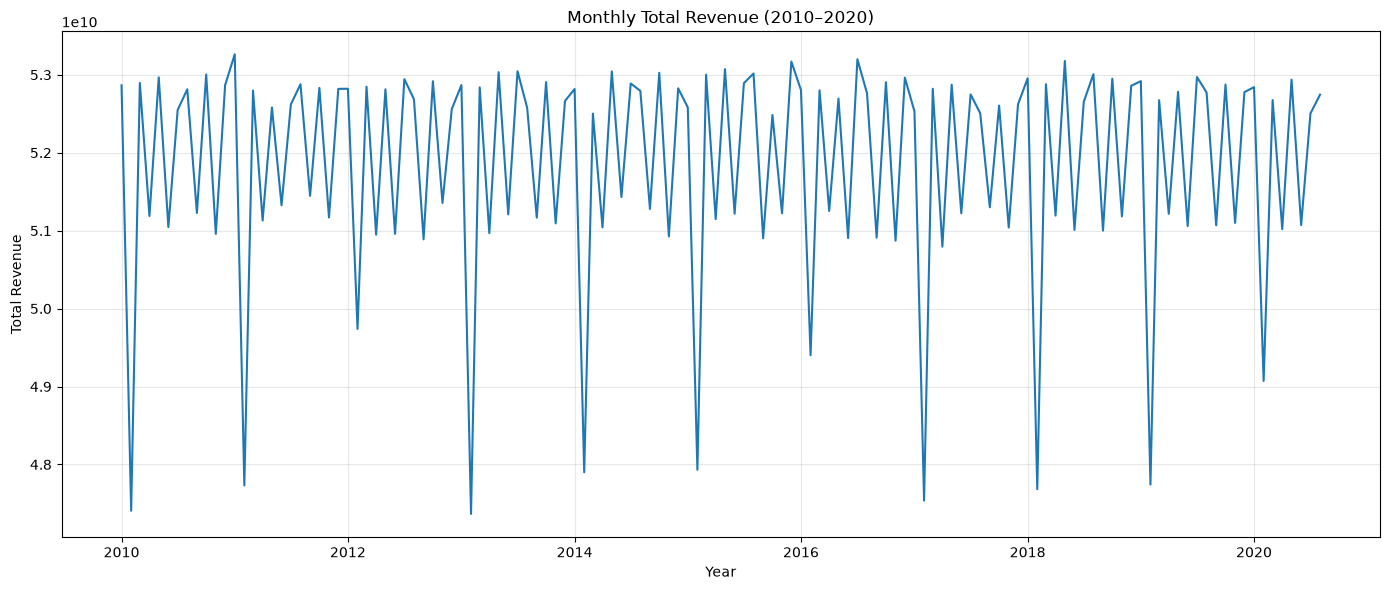

In [94]:
# Convert PeriodIndex to timestamps for plotting
plot_data = monthly_revenue_clean.copy()
plot_data.index = plot_data.index.to_timestamp()

plt.figure(figsize=(14, 6))

plt.plot(
    plot_data.index,
    plot_data["Total Revenue"]
)

plt.title("Monthly Total Revenue (2010–2020)")
plt.xlabel("Year")
plt.ylabel("Total Revenue")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [95]:
# 80:20 chronological train-test split

split_index = int(len(monthly_revenue_clean) * 0.80)

train = monthly_revenue_clean.iloc[:split_index].copy()
test = monthly_revenue_clean.iloc[split_index:].copy()

print("Total observations:", len(monthly_revenue_clean))
print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Total observations: 128
Training observations: 102
Testing observations: 26

Training period:
2010-01 to 2018-06

Testing period:
2018-07 to 2020-08


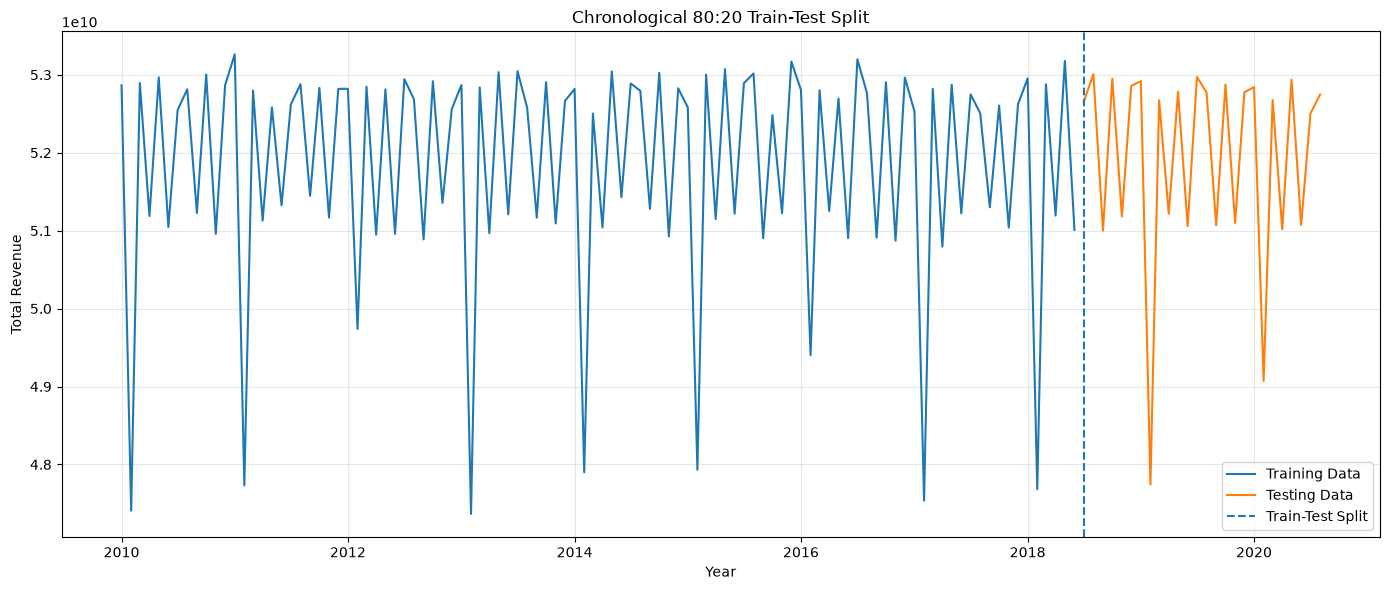

In [96]:
train_plot = train.copy()
test_plot = test.copy()

train_plot.index = train_plot.index.to_timestamp()
test_plot.index = test_plot.index.to_timestamp()

plt.figure(figsize=(14, 6))

plt.plot(
    train_plot.index,
    train_plot["Total Revenue"],
    label="Training Data"
)

plt.plot(
    test_plot.index,
    test_plot["Total Revenue"],
    label="Testing Data"
)

plt.axvline(
    x=test_plot.index[0],
    linestyle="--",
    label="Train-Test Split"
)

plt.title("Chronological 80:20 Train-Test Split")
plt.xlabel("Year")
plt.ylabel("Total Revenue")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

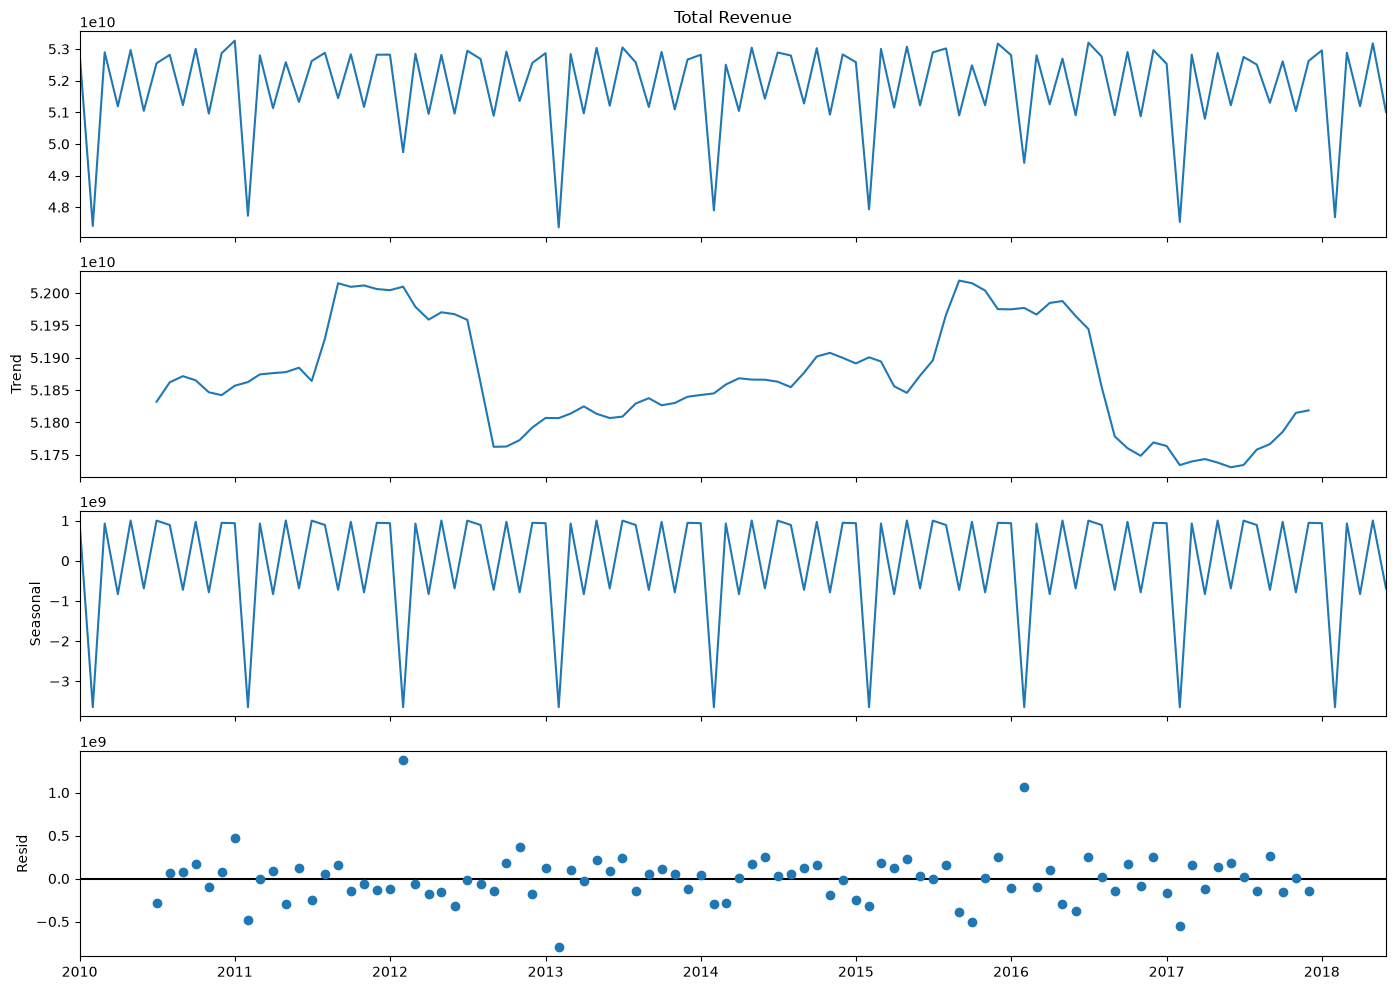

In [97]:
# Convert training index from PeriodIndex to DatetimeIndex
train_decomp = train.copy()
train_decomp.index = train_decomp.index.to_timestamp()

# Seasonal decomposition with yearly seasonality
decomposition = seasonal_decompose(
    train_decomp["Total Revenue"],
    model="additive",
    period=12
)

fig = decomposition.plot()
fig.set_size_inches(14, 10)
plt.tight_layout()
plt.show()

In [98]:
# ADF stationarity test

adf_result = adfuller(train["Total Revenue"])

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

print("\nCritical Values:")
for key, value in adf_result[4].items():
    print(f"{key}: {value}")

if adf_result[1] <= 0.05:
    print("\nResult: The series is STATIONARY.")
else:
    print("\nResult: The series is NON-STATIONARY.")

ADF Statistic: -2.1119342609276424
p-value: 0.23974293260169455

Critical Values:
1%: -3.505190196159122
5%: -2.894232085048011
10%: -2.5842101234567902

Result: The series is NON-STATIONARY.


In [99]:
# first-order differencing
train_diff = train["Total Revenue"].diff().dropna()

print("Original training observations:", len(train))
print("After first differencing:", len(train_diff))

display(train_diff.head())

Original training observations: 102
After first differencing: 101


Month
2010-02   -5.457644e+09
2010-03    5.488047e+09
2010-04   -1.706991e+09
2010-05    1.778616e+09
2010-06   -1.920628e+09
Freq: M, Name: Total Revenue, dtype: float64

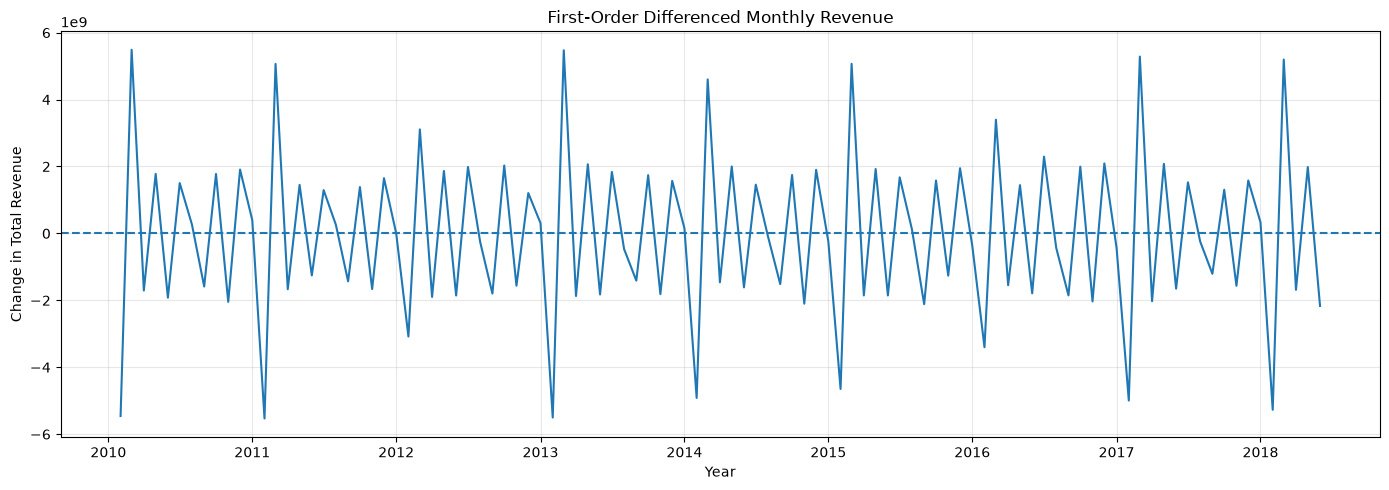

In [100]:
plt.figure(figsize=(14, 5))

plt.plot(
    train_diff.index.to_timestamp(),
    train_diff
)

plt.axhline(y=0, linestyle="--")

plt.title("First-Order Differenced Monthly Revenue")
plt.xlabel("Year")
plt.ylabel("Change in Total Revenue")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [101]:
adf_diff = adfuller(train_diff)

print("ADF Statistic:", adf_diff[0])
print("p-value:", adf_diff[1])

print("\nCritical Values:")
for key, value in adf_diff[4].items():
    print(f"{key}: {value}")

if adf_diff[1] <= 0.05:
    print("\nResult: Differenced series is STATIONARY.")
else:
    print("\nResult: Differenced series is still NON-STATIONARY.")

ADF Statistic: -18.650132832676782
p-value: 2.0510472306644234e-30

Critical Values:
1%: -3.505190196159122
5%: -2.894232085048011
10%: -2.5842101234567902

Result: Differenced series is STATIONARY.


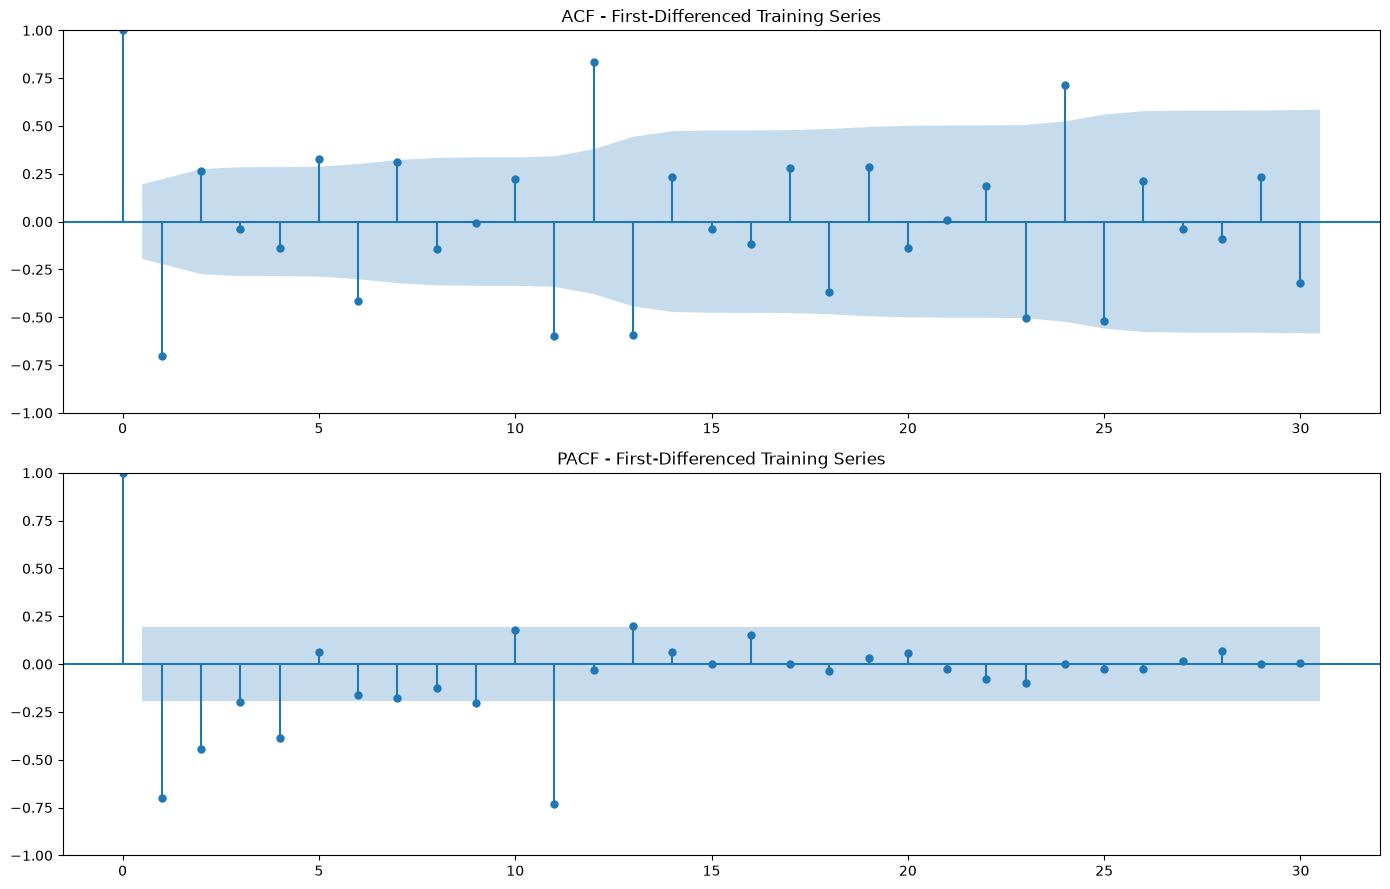

In [102]:
# ACF — Autocorrelation Function and PACF — Partial Autocorrelation Function

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

plot_acf(
    train_diff,
    lags=30,
    ax=axes[0],
    alpha=0.05
)

axes[0].set_title("ACF - First-Differenced Training Series")

plot_pacf(
    train_diff,
    lags=30,
    ax=axes[1],
    alpha=0.05,
    method="ywm"
)

axes[1].set_title("PACF - First-Differenced Training Series")

plt.tight_layout()
plt.show()

In [103]:
# Significant ACF and PACF lags
max_lag = 30

acf_values, acf_confint = acf(
    train_diff,
    nlags=max_lag,
    alpha=0.05
)

pacf_values, pacf_confint = pacf(
    train_diff,
    nlags=max_lag,
    alpha=0.05,
    method="ywm"
)

significant_acf_lags = []
significant_pacf_lags = []

for lag in range(1, max_lag + 1):

    # Confidence interval around zero
    acf_lower = acf_confint[lag][0] - acf_values[lag]
    acf_upper = acf_confint[lag][1] - acf_values[lag]

    pacf_lower = pacf_confint[lag][0] - pacf_values[lag]
    pacf_upper = pacf_confint[lag][1] - pacf_values[lag]

    if acf_values[lag] < acf_lower or acf_values[lag] > acf_upper:
        significant_acf_lags.append(lag)

    if pacf_values[lag] < pacf_lower or pacf_values[lag] > pacf_upper:
        significant_pacf_lags.append(lag)

print("Significant ACF lags :", significant_acf_lags)
print("Significant PACF lags:", significant_pacf_lags)

Significant ACF lags : [1, 5, 6, 11, 12, 13, 24]
Significant PACF lags: [1, 2, 3, 4, 9, 11, 13]


In [104]:
# Create the final lag set
significant_lags = significant_acf_lags

fixed_lags = [1, 2, 7, 12]

final_lags = sorted(
    set(significant_lags + fixed_lags)
)

print("Statistically significant lags:", significant_lags)
print("Fixed lags:", fixed_lags)
print("Final Vaticinator lag set:", final_lags)
print("Number of selected lags:", len(final_lags))

Statistically significant lags: [1, 5, 6, 11, 12, 13, 24]
Fixed lags: [1, 2, 7, 12]
Final Vaticinator lag set: [1, 2, 5, 6, 7, 11, 12, 13, 24]
Number of selected lags: 9


In [105]:
# Function to create lag-based supervised samples

def create_lagged_samples(series, lags):
    
    X = []
    y = []
    
    max_lag = max(lags)

    # Works with both Pandas Series and NumPy arrays
    values = np.asarray(series).flatten()

    for i in range(max_lag, len(values)):
        
        lag_values = [
            values[i - lag]
            for lag in lags
        ]
        
        X.append(lag_values)
        y.append(values[i])

    return np.array(X), np.array(y)

In [106]:
X_train, y_train = create_lagged_samples(
    train["Total Revenue"],
    final_lags
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nFirst input sample:")
print(X_train[0])

print("\nFirst target:")
print(y_train[0])

X_train shape: (78, 9)
y_train shape: (78,)

First input sample:
[5.28189153e+10 5.11684178e+10 5.28786802e+10 5.26195560e+10
 5.13255862e+10 4.77308089e+10 5.32623969e+10 5.28665839e+10
 5.28642694e+10]

First target:
52820576511.35


In [107]:
# standardizing the series

scaler = StandardScaler()

# Fit ONLY on training data
train_scaled = scaler.fit_transform(
    train[["Total Revenue"]]
).flatten()

print("Original first 5 values:")
print(train["Total Revenue"].head().values)

print("\nScaled first 5 values:")
print(train_scaled[:5])

print("\nScaled mean:", train_scaled.mean())
print("Scaled standard deviation:", train_scaled.std())

Original first 5 values:
[5.28642694e+10 4.74066251e+10 5.28946722e+10 5.11876814e+10
 5.29662971e+10]

Scaled first 5 values:
[ 0.70905165 -3.06836641  0.73009444 -0.45137095  0.77966838]

Scaled mean: 3.855303875708142e-15
Scaled standard deviation: 1.0


In [108]:
train_scaled_series = pd.Series(
    train_scaled,
    index=train.index
)

X_train_scaled, y_train_scaled = create_lagged_samples(
    train_scaled_series,
    final_lags
)

print("X_train_scaled shape:", X_train_scaled.shape)
print("y_train_scaled shape:", y_train_scaled.shape)

print("\nFirst scaled input:")
print(X_train_scaled[0])

print("\nFirst scaled target:")
print(y_train_scaled[0])

X_train_scaled shape: (78, 9)
y_train_scaled shape: (78,)

First scaled input:
[ 0.67766055 -0.46470394  0.7190258   0.5396773  -0.35592244 -2.84398794
  0.98460895  0.71065358  0.70905165]

First scaled target:
0.6788103208771884


In [109]:
# Scale test data using the SAME scaler fitted on training data

test_scaled = scaler.transform(
    test[["Total Revenue"]]
).flatten()

print("First 5 scaled test values:")
print(test_scaled[:5])

print("\nNumber of test values:", len(test_scaled))

First 5 scaled test values:
[ 0.56289891  0.80876824 -0.58097613  0.76862572 -0.45525359]

Number of test values: 26


In [110]:
# Maximum historical lag required
max_lag = max(final_lags)

# Combine last 24 training values with all test values
test_context = np.concatenate([
    train_scaled[-max_lag:],
    test_scaled
])

X_test_scaled = []
y_test_scaled = []

# Start at max_lag so targets begin exactly at first test month
for i in range(max_lag, len(test_context)):
    
    lag_values = [
        test_context[i - lag]
        for lag in final_lags
    ]
    
    X_test_scaled.append(lag_values)
    y_test_scaled.append(test_context[i])

X_test_scaled = np.array(X_test_scaled)
y_test_scaled = np.array(y_test_scaled)

print("X_test_scaled shape:", X_test_scaled.shape)
print("y_test_scaled shape:", y_test_scaled.shape)

print("\nFirst test input:")
print(X_test_scaled[0])

print("\nFirst test target:")
print(y_test_scaled[0])

X_test_scaled shape: (26, 9)
y_test_scaled shape: (26,)

First test input:
[-0.57492491  0.92543294 -2.87704314  0.77145707  0.5414107   0.46156771
  0.62848491 -0.42748576  0.94064346]

First test target:
0.5628989108752458


In [111]:
# Convert training and testing arrays to PyTorch tensors

X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_scaled,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test_scaled,
    dtype=torch.float32
)

print("X_train_tensor shape:", X_train_tensor.shape)
print("y_train_tensor shape:", y_train_tensor.shape)

print("X_test_tensor shape:", X_test_tensor.shape)
print("y_test_tensor shape:", y_test_tensor.shape)

X_train_tensor shape: torch.Size([78, 9])
y_train_tensor shape: torch.Size([78])
X_test_tensor shape: torch.Size([26, 9])
y_test_tensor shape: torch.Size([26])


In [112]:
X_train_tensor = X_train_tensor.unsqueeze(-1)
X_test_tensor = X_test_tensor.unsqueeze(-1)

print("X_train after unsqueeze:", X_train_tensor.shape)
print("X_test after unsqueeze:", X_test_tensor.shape)

X_train after unsqueeze: torch.Size([78, 9, 1])
X_test after unsqueeze: torch.Size([26, 9, 1])


In [113]:
# create the embedding layer
d_model = 32

embedding_layer = nn.Linear(
    in_features=1,
    out_features=d_model
)

embedded_train = embedding_layer(X_train_tensor)

print("Before embedding:", X_train_tensor.shape)
print("After embedding :", embedded_train.shape)

Before embedding: torch.Size([78, 9, 1])
After embedding : torch.Size([78, 9, 32])


In [114]:
class LagAwarePositionalEncoding(nn.Module):
    
    def __init__(self, d_model):
        super().__init__()
        self.d_model = d_model
    
    def forward(self, x, lags):
        
        # x shape: [batch_size, num_lags, d_model]
        
        device = x.device
        
        # Actual lag positions
        positions = torch.tensor(
            lags,
            dtype=torch.float32,
            device=device
        ).unsqueeze(1)
        
        # Create dimensions 0, 2, 4, ...
        div_term = torch.exp(
            torch.arange(
                0,
                self.d_model,
                2,
                device=device
            ).float()
            * (-math.log(10000.0) / self.d_model)
        )
        
        pe = torch.zeros(
            len(lags),
            self.d_model,
            device=device
        )
        
        # Sine for even positions
        pe[:, 0::2] = torch.sin(
            positions * div_term
        )
        
        # Cosine for odd positions
        pe[:, 1::2] = torch.cos(
            positions * div_term
        )
        
        # Add batch dimension
        pe = pe.unsqueeze(0)
        
        return x + pe

In [115]:
#positional encoding based on the actual lag value
pos_encoder = LagAwarePositionalEncoding(
    d_model=32
)

encoded_train = pos_encoder(
    embedded_train,
    final_lags
)

print("Before positional encoding:", embedded_train.shape)
print("After positional encoding :", encoded_train.shape)

Before positional encoding: torch.Size([78, 9, 32])
After positional encoding : torch.Size([78, 9, 32])


In [116]:
# Adding attention
encoder_layer = nn.TransformerEncoderLayer(
    d_model=32,
    nhead=8,
    dim_feedforward=128,
    activation="relu",
    batch_first=True
)

transformer_encoder = nn.TransformerEncoder(
    encoder_layer,
    num_layers=3
)

transformer_output = transformer_encoder(
    encoded_train
)

print("Input to Transformer :", encoded_train.shape)
print("Output from Transformer:", transformer_output.shape)

Input to Transformer : torch.Size([78, 9, 32])
Output from Transformer: torch.Size([78, 9, 32])


In [117]:
# Take the final token representation
final_representation = transformer_output[:, -1, :]

print("Transformer output shape:",
      transformer_output.shape)

print("Final representation shape:",
      final_representation.shape)

Transformer output shape: torch.Size([78, 9, 32])
Final representation shape: torch.Size([78, 32])


In [118]:
output_layer = nn.Linear(
    in_features=32,
    out_features=1
)

predictions = output_layer(
    final_representation
)

print("Prediction shape:",
      predictions.shape)

print("\nFirst 5 predictions:")
print(predictions[:5])

Prediction shape: torch.Size([78, 1])

First 5 predictions:
tensor([[0.3978],
        [0.4905],
        [0.5965],
        [0.6310],
        [0.5469]], grad_fn=<SliceBackward0>)


In [119]:
# Vaticinator class
class Vaticinator(nn.Module):

    def __init__(
        self,
        lags,
        d_model=32,
        nhead=8,
        num_layers=3,
        dim_feedforward=128
    ):
        super().__init__()

        self.lags = lags
        self.d_model = d_model

        # 1. Scalar lag value -> 32-dimensional embedding
        self.embedding = nn.Linear(1, d_model)

        # 2. Transformer encoder layer
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            activation="relu",
            batch_first=True
        )

        # 3. Stack 3 Transformer encoder layers
        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # 4. Final 32-dimensional representation -> 1 forecast
        self.output_layer = nn.Linear(d_model, 1)


    def lag_positional_encoding(self, x):

        positions = torch.tensor(
            self.lags,
            dtype=torch.float32,
            device=x.device
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(
                0,
                self.d_model,
                2,
                device=x.device
            ).float()
            * (-math.log(10000.0) / self.d_model)
        )

        pe = torch.zeros(
            len(self.lags),
            self.d_model,
            device=x.device
        )

        pe[:, 0::2] = torch.sin(
            positions * div_term
        )

        pe[:, 1::2] = torch.cos(
            positions * div_term
        )

        return x + pe.unsqueeze(0)


    def forward(self, x):

        # x: [batch, 9, 1]

        # Scalar embedding
        x = self.embedding(x)

        # [batch, 9, 32]

        # Add actual lag-position information
        x = self.lag_positional_encoding(x)

        # Transformer
        x = self.transformer(x)

        # Take final transformed token
        x = x[:, -1, :]

        # Produce one forecast
        x = self.output_layer(x)

        return x.squeeze(-1)

In [120]:
# Model
model = Vaticinator(
    lags=final_lags,
    d_model=32,
    nhead=8,
    num_layers=3
)

print(model)

Vaticinator(
  (embedding): Linear(in_features=1, out_features=32, bias=True)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
        )
        (linear1): Linear(in_features=32, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=32, bias=True)
        (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
)


In [121]:
with torch.no_grad():

    test_output = model(
        X_train_tensor
    )

print("Input shape :", X_train_tensor.shape)
print("Output shape:", test_output.shape)

print("\nFirst 5 untrained predictions:")
print(test_output[:5])

Input shape : torch.Size([78, 9, 1])
Output shape: torch.Size([78])

First 5 untrained predictions:
tensor([ 0.7761, -0.3605,  0.6010,  0.2932,  0.7949])


In [122]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

num_epochs = 100

train_losses = []

for epoch in range(num_epochs):

    # Training mode
    model.train()

    # Clear old gradients
    optimizer.zero_grad()

    # Forward pass
    predictions = model(X_train_tensor)

    # Calculate error
    loss = criterion(
        predictions,
        y_train_tensor
    )

    # Backpropagation
    loss.backward()

    # Update model weights
    optimizer.step()

    # Store loss
    train_losses.append(loss.item())

    # Print every 10 epochs
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{num_epochs}], "
            f"Loss: {loss.item():.6f}"
        )

Epoch [10/100], Loss: 0.348820
Epoch [20/100], Loss: 0.230691
Epoch [30/100], Loss: 0.146798
Epoch [40/100], Loss: 0.126011
Epoch [50/100], Loss: 0.130194
Epoch [60/100], Loss: 0.088384
Epoch [70/100], Loss: 0.107430
Epoch [80/100], Loss: 0.098113
Epoch [90/100], Loss: 0.085499
Epoch [100/100], Loss: 0.100599


In [123]:
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=False
)

model = Vaticinator(
    lags=final_lags,
    d_model=32,
    nhead=8,
    num_layers=3
)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

num_epochs = 100
train_losses = []

for epoch in range(num_epochs):

    model.train()

    epoch_loss = 0.0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{num_epochs}], "
            f"Loss: {avg_loss:.6f}"
        )

Epoch [10/100], Loss: 0.213464
Epoch [20/100], Loss: 0.130796
Epoch [30/100], Loss: 0.109346
Epoch [40/100], Loss: 0.097005
Epoch [50/100], Loss: 0.091474
Epoch [60/100], Loss: 0.091959
Epoch [70/100], Loss: 0.088639
Epoch [80/100], Loss: 0.072855
Epoch [90/100], Loss: 0.069761
Epoch [100/100], Loss: 0.071511


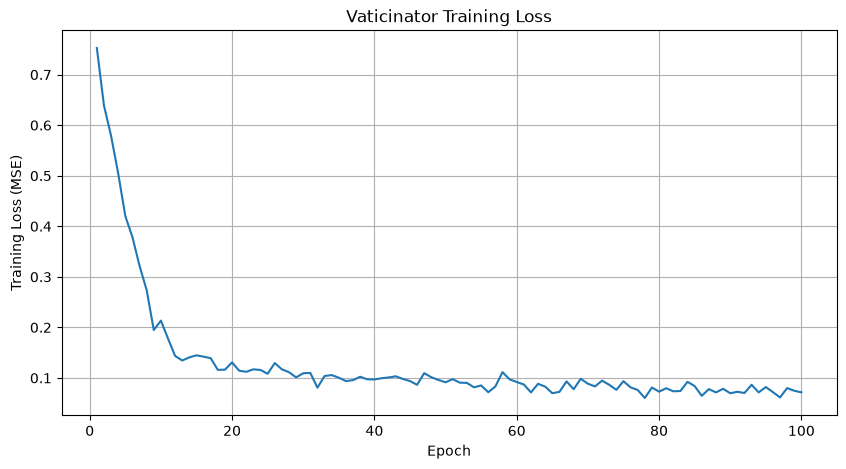

In [124]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, num_epochs + 1),
    train_losses
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss (MSE)")
plt.title("Vaticinator Training Loss")
plt.grid(True)

plt.show()

In [125]:
# Test data 
model.eval()

with torch.no_grad():

    test_predictions_scaled = model(
        X_test_tensor
    )

print("Prediction shape:",
      test_predictions_scaled.shape)

print("\nFirst 5 scaled predictions:")
print(test_predictions_scaled[:5])

Prediction shape: torch.Size([26])

First 5 scaled predictions:
tensor([ 0.7587,  0.6650, -0.8053,  0.6801, -0.7463])


In [126]:
test_predictions = scaler.inverse_transform(
    test_predictions_scaled
        .cpu()
        .numpy()
        .reshape(-1, 1)
).flatten()

actual_test = scaler.inverse_transform(
    y_test_tensor
        .cpu()
        .numpy()
        .reshape(-1, 1)
).flatten()

print("First 5 predicted revenues:")
print(test_predictions[:5])

print("\nFirst 5 actual revenues:")
print(actual_test[:5])

First 5 predicted revenues:
[5.2935983e+10 5.2800635e+10 5.0676253e+10 5.2822508e+10 5.0761527e+10]

First 5 actual revenues:
[5.2653105e+10 5.3008339e+10 5.1000426e+10 5.2950340e+10 5.1182068e+10]


In [127]:
# evaluation metrics
rmse = np.sqrt(
    mean_squared_error(
        actual_test,
        test_predictions
    )
)

mae = mean_absolute_error(
    actual_test,
    test_predictions
)

mape = np.mean(
    np.abs(
        (actual_test - test_predictions)
        / actual_test
    )
) * 100

nrmse = rmse / np.mean(actual_test)

nmae = mae / np.mean(actual_test)

mapa = 100 - mape

mpe = np.mean(
    (actual_test - test_predictions)
    / actual_test
) * 100


print(f"RMSE  : {rmse:,.2f}")
print(f"MAE   : {mae:,.2f}")
print(f"NRMSE : {nrmse:.4f}")
print(f"NMAE  : {nmae:.4f}")
print(f"MAPE  : {mape:.4f}%")
print(f"MAPA  : {mapa:.4f}%")
print(f"MPE   : {mpe:.4f}%")

RMSE  : 297,152,654.48
MAE   : 223,719,904.00
NRMSE : 0.0057
NMAE  : 0.0043
MAPE  : 0.4375%
MAPA  : 99.5625%
MPE   : 0.1401%


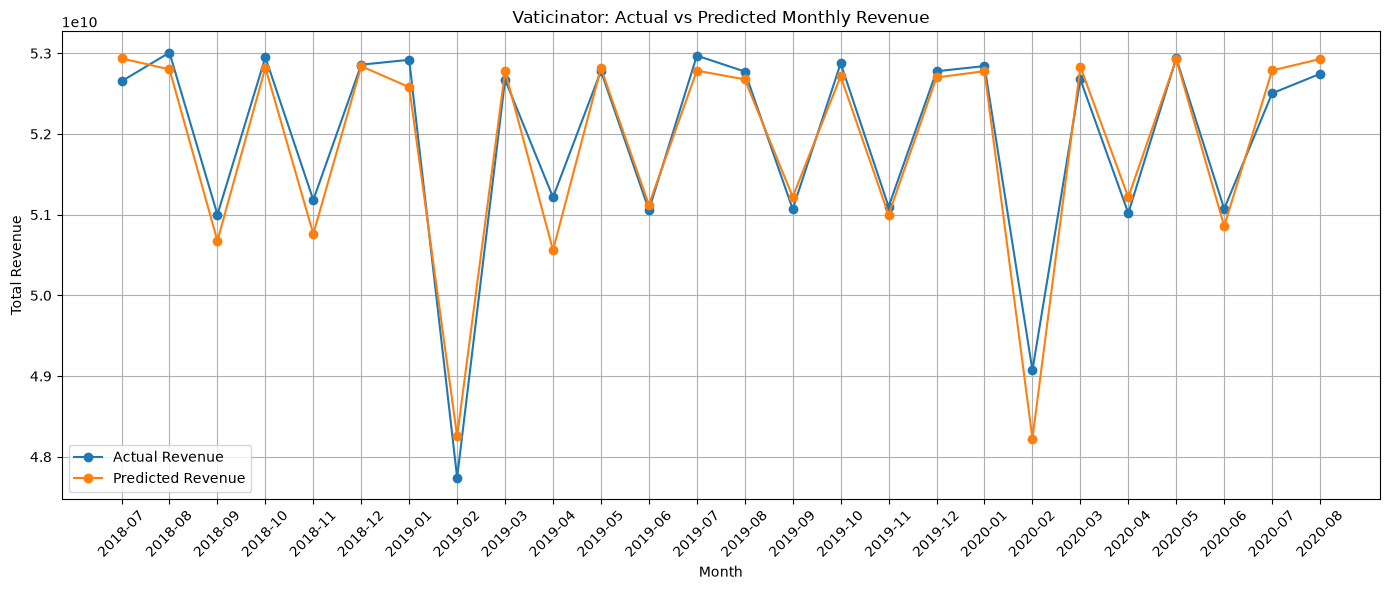

In [128]:
test_dates = test.index

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates.astype(str),
    actual_test,
    marker="o",
    label="Actual Revenue"
)

plt.plot(
    test_dates.astype(str),
    test_predictions,
    marker="o",
    label="Predicted Revenue"
)

plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.title("Vaticinator: Actual vs Predicted Monthly Revenue")

plt.xticks(rotation=45)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [129]:
# Recursive forecasting function

def recursive_forecast(
    model,
    train_scaled,
    lags,
    forecast_horizon
):
    
    model.eval()
    
    # Start with all known training history
    history = list(train_scaled.copy())
    
    recursive_predictions = []
    
    with torch.no_grad():
        
        for step in range(forecast_horizon):
            
            # Get selected lag values from current history
            lag_values = [
                history[-lag]
                for lag in lags
            ]
            
            # Convert to tensor
            X_input = torch.tensor(
                lag_values,
                dtype=torch.float32
            ).reshape(1, len(lags), 1)
            
            # Predict next month
            prediction = model(X_input).item()
            
            # Store prediction
            recursive_predictions.append(prediction)
            
            # IMPORTANT:
            # prediction becomes part of history
            history.append(prediction)
    
    return np.array(recursive_predictions)

In [130]:
recursive_predictions_scaled = recursive_forecast(
    model=model,
    train_scaled=train_scaled,
    lags=final_lags,
    forecast_horizon=len(test)
)

print(
    "Number of recursive predictions:",
    len(recursive_predictions_scaled)
)

print(
    "First 5 scaled predictions:",
    recursive_predictions_scaled[:5]
)

Number of recursive predictions: 26
First 5 scaled predictions: [ 0.75868732  0.66184092 -0.80867076  0.69138491 -0.73766828]


In [131]:
# inverse transform + recursive metrics
recursive_predictions = scaler.inverse_transform(
    recursive_predictions_scaled.reshape(-1, 1)
).flatten()

print("First 5 recursive revenue predictions:")
print(recursive_predictions[:5])

First 5 recursive revenue predictions:
[5.29359834e+10 5.27960590e+10 5.06714517e+10 5.28387444e+10
 5.07740367e+10]


In [132]:
recursive_rmse = np.sqrt(
    mean_squared_error(
        actual_test,
        recursive_predictions
    )
)

recursive_mae = mean_absolute_error(
    actual_test,
    recursive_predictions
)

recursive_mape = np.mean(
    np.abs(
        (actual_test - recursive_predictions)
        / actual_test
    )
) * 100

recursive_nrmse = (
    recursive_rmse / np.mean(actual_test)
)

recursive_nmae = (
    recursive_mae / np.mean(actual_test)
)

recursive_mapa = 100 - recursive_mape

recursive_mpe = np.mean(
    (actual_test - recursive_predictions)
    / actual_test
) * 100


print("RECURSIVE FORECAST RESULTS")
print("--------------------------")

print(f"RMSE  : {recursive_rmse:,.2f}")
print(f"MAE   : {recursive_mae:,.2f}")
print(f"NRMSE : {recursive_nrmse:.4f}")
print(f"NMAE  : {recursive_nmae:.4f}")
print(f"MAPE  : {recursive_mape:.4f}%")
print(f"MAPA  : {recursive_mapa:.4f}%")
print(f"MPE   : {recursive_mpe:.4f}%")

RECURSIVE FORECAST RESULTS
--------------------------
RMSE  : 294,504,793.60
MAE   : 219,077,739.02
NRMSE : 0.0057
NMAE  : 0.0042
MAPE  : 0.4287%
MAPA  : 99.5713%
MPE   : 0.1147%


In [133]:
print("ONE-STEP vs RECURSIVE")
print("---------------------")

print(
    f"One-Step  MAPE : {mape:.4f}%"
)

print(
    f"Recursive MAPE : {recursive_mape:.4f}%"
)

print()

print(
    f"One-Step  MAPA : {mapa:.4f}%"
)

print(
    f"Recursive MAPA : {recursive_mapa:.4f}%"
)

print()

print(
    f"One-Step  RMSE : {rmse:,.2f}"
)

print(
    f"Recursive RMSE : {recursive_rmse:,.2f}"
)

ONE-STEP vs RECURSIVE
---------------------
One-Step  MAPE : 0.4375%
Recursive MAPE : 0.4287%

One-Step  MAPA : 99.5625%
Recursive MAPA : 99.5713%

One-Step  RMSE : 297,152,654.48
Recursive RMSE : 294,504,793.60


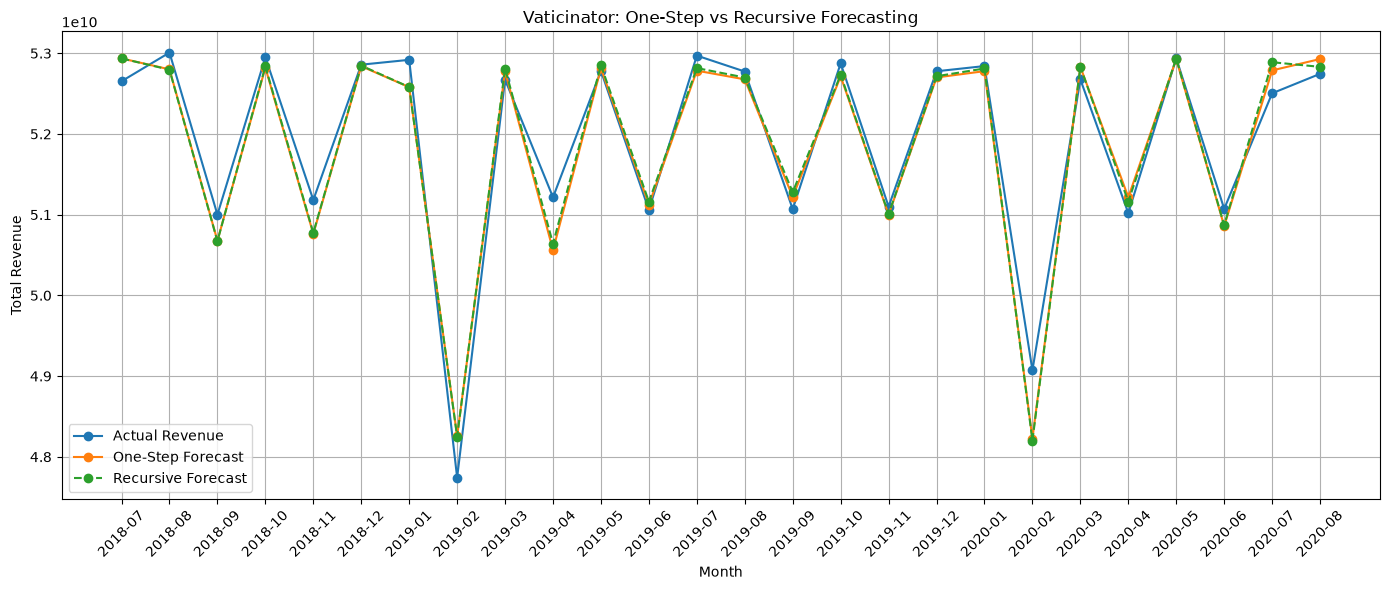

In [134]:
plt.figure(figsize=(14, 6))

plt.plot(
    test_dates.astype(str),
    actual_test,
    marker="o",
    label="Actual Revenue"
)

plt.plot(
    test_dates.astype(str),
    test_predictions,
    marker="o",
    label="One-Step Forecast"
)

plt.plot(
    test_dates.astype(str),
    recursive_predictions,
    marker="o",
    linestyle="--",
    label="Recursive Forecast"
)

plt.xlabel("Month")
plt.ylabel("Total Revenue")

plt.title(
    "Vaticinator: One-Step vs Recursive Forecasting"
)

plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [135]:
# Combine train and test series
full_series = pd.concat([train, test])

seasonal_naive_predictions = []

# Position where test period begins
test_start = len(train)

for i in range(len(test)):
    
    current_position = test_start + i
    
    # Forecast = actual value 12 months earlier
    prediction = full_series.iloc[
        current_position - 12
    ]["Total Revenue"]
    
    seasonal_naive_predictions.append(prediction)

seasonal_naive_predictions = np.array(
    seasonal_naive_predictions
)

print(
    "Number of predictions:",
    len(seasonal_naive_predictions)
)

print("\nFirst 5 Seasonal Naive predictions:")
print(seasonal_naive_predictions[:5])

Number of predictions: 26

First 5 Seasonal Naive predictions:
[5.27478660e+10 5.25067026e+10 5.13000136e+10 5.26052404e+10
 5.10396957e+10]


In [136]:
seasonal_naive_mape = np.mean(
    np.abs(
        (actual_test - seasonal_naive_predictions)
        / actual_test
    )
) * 100

seasonal_naive_mapa = 100 - seasonal_naive_mape

seasonal_naive_rmse = np.sqrt(
    mean_squared_error(
        actual_test,
        seasonal_naive_predictions
    )
)

print("SEASONAL NAIVE RESULTS")
print("----------------------")

print(
    f"RMSE : {seasonal_naive_rmse:,.2f}"
)

print(
    f"MAPE : {seasonal_naive_mape:.4f}%"
)

print(
    f"MAPA : {seasonal_naive_mapa:.4f}%"
)

SEASONAL NAIVE RESULTS
----------------------
RMSE : 338,960,324.94
MAPE : 0.4119%
MAPA : 99.5881%


# Dense Transformer

In [137]:
dense_lags = list(range(1, 25))

print("Dense Transformer lags:")
print(dense_lags)

print("Number of lags:", len(dense_lags))

Dense Transformer lags:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]
Number of lags: 24


In [138]:
X_train_dense, y_train_dense = create_lagged_samples(
    train_scaled,
    dense_lags
)

print("Dense X_train shape:", X_train_dense.shape)
print("Dense y_train shape:", y_train_dense.shape)

Dense X_train shape: (78, 24)
Dense y_train shape: (78,)


In [139]:
X_train_dense_tensor = torch.tensor(
    X_train_dense,
    dtype=torch.float32
).unsqueeze(-1)

y_train_dense_tensor = torch.tensor(
    y_train_dense,
    dtype=torch.float32
)

print("X_train_dense_tensor:", X_train_dense_tensor.shape)
print("y_train_dense_tensor:", y_train_dense_tensor.shape)

X_train_dense_tensor: torch.Size([78, 24, 1])
y_train_dense_tensor: torch.Size([78])


In [140]:
dense_window = 24

# Last 24 months of training + complete test period
dense_test_context = np.concatenate([
    train_scaled[-dense_window:],
    test_scaled
])

X_test_dense = []
y_test_dense = []

for i in range(dense_window, len(dense_test_context)):
    
    # Previous 24 consecutive months
    window = dense_test_context[
        i - dense_window:i
    ]
    
    # Reverse so order corresponds to:
    # lag 1, lag 2, ..., lag 24
    window = window[::-1].copy()
    
    X_test_dense.append(window)
    y_test_dense.append(
        dense_test_context[i]
    )

X_test_dense = np.array(X_test_dense)
y_test_dense = np.array(y_test_dense)

print("Dense X_test shape:", X_test_dense.shape)
print("Dense y_test shape:", y_test_dense.shape)

Dense X_test shape: (26, 24)
Dense y_test shape: (26,)


In [141]:
X_test_dense_tensor = torch.tensor(
    X_test_dense,
    dtype=torch.float32
).unsqueeze(-1)

y_test_dense_tensor = torch.tensor(
    y_test_dense,
    dtype=torch.float32
)

print(
    "X_test_dense_tensor:",
    X_test_dense_tensor.shape
)

print(
    "y_test_dense_tensor:",
    y_test_dense_tensor.shape
)

X_test_dense_tensor: torch.Size([26, 24, 1])
y_test_dense_tensor: torch.Size([26])


In [142]:
class DenseTransformer(nn.Module):

    def __init__(
        self,
        window_size=24,
        d_model=32,
        nhead=8,
        num_layers=3,
        dim_feedforward=128
    ):
        super().__init__()

        self.window_size = window_size
        self.d_model = d_model

        # Convert each scalar revenue value -> 32 dimensions
        self.embedding = nn.Linear(1, d_model)

        # Transformer encoder layer
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            activation="relu",
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # Final representation -> one forecast
        self.output_layer = nn.Linear(
            d_model,
            1
        )


    def positional_encoding(self, x):

        # Positions correspond to lag 1 ... lag 24
        positions = torch.arange(
            1,
            self.window_size + 1,
            dtype=torch.float32,
            device=x.device
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(
                0,
                self.d_model,
                2,
                device=x.device
            ).float()
            * (-math.log(10000.0) / self.d_model)
        )

        pe = torch.zeros(
            self.window_size,
            self.d_model,
            device=x.device
        )

        pe[:, 0::2] = torch.sin(
            positions * div_term
        )

        pe[:, 1::2] = torch.cos(
            positions * div_term
        )

        return x + pe.unsqueeze(0)


    def forward(self, x):

        # [batch, 24, 1]
        x = self.embedding(x)

        # [batch, 24, 32]
        x = self.positional_encoding(x)

        # Transformer
        x = self.transformer(x)

        # Final transformed token
        x = x[:, -1, :]

        # Forecast
        x = self.output_layer(x)

        return x.squeeze(-1)

In [143]:
dense_model = DenseTransformer(
    window_size=24,
    d_model=32,
    nhead=8,
    num_layers=3
)

print(dense_model)

DenseTransformer(
  (embedding): Linear(in_features=1, out_features=32, bias=True)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=32, out_features=32, bias=True)
        )
        (linear1): Linear(in_features=32, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=32, bias=True)
        (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
)


In [144]:
with torch.no_grad():

    dense_test_output = dense_model(
        X_train_dense_tensor
    )

print(
    "Dense input shape :",
    X_train_dense_tensor.shape
)

print(
    "Dense output shape:",
    dense_test_output.shape
)

Dense input shape : torch.Size([78, 24, 1])
Dense output shape: torch.Size([78])


In [145]:
dense_train_dataset = TensorDataset(
    X_train_dense_tensor,
    y_train_dense_tensor
)

dense_train_loader = DataLoader(
    dense_train_dataset,
    batch_size=16,
    shuffle=False
)

criterion = nn.MSELoss()

dense_optimizer = torch.optim.Adam(
    dense_model.parameters(),
    lr=0.0001
)

num_epochs = 100
dense_train_losses = []

for epoch in range(num_epochs):

    dense_model.train()

    epoch_loss = 0.0

    for X_batch, y_batch in dense_train_loader:

        dense_optimizer.zero_grad()

        predictions = dense_model(X_batch)

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        dense_optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(dense_train_loader)
    dense_train_losses.append(avg_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{num_epochs}], "
            f"Loss: {avg_loss:.6f}"
        )

Epoch [10/100], Loss: 0.252928
Epoch [20/100], Loss: 0.130084
Epoch [30/100], Loss: 0.112757
Epoch [40/100], Loss: 0.087840
Epoch [50/100], Loss: 0.085559
Epoch [60/100], Loss: 0.097269
Epoch [70/100], Loss: 0.081123
Epoch [80/100], Loss: 0.077755
Epoch [90/100], Loss: 0.067071
Epoch [100/100], Loss: 0.070647


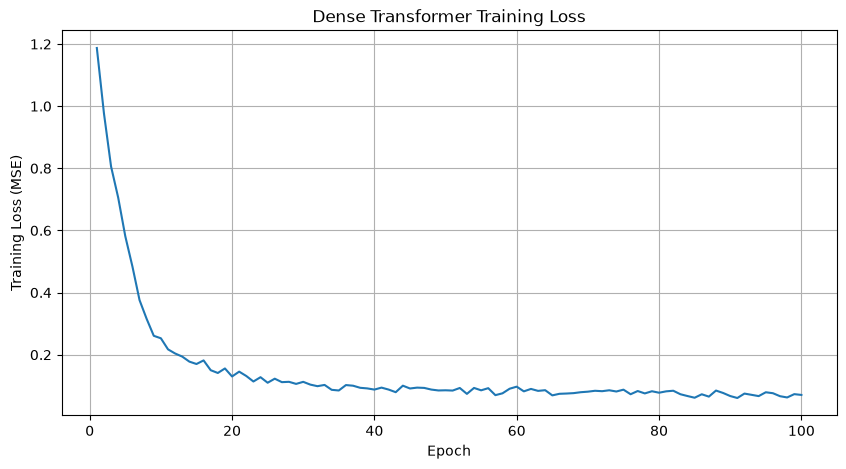

In [146]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, num_epochs + 1),
    dense_train_losses
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss (MSE)")
plt.title("Dense Transformer Training Loss")
plt.grid(True)

plt.show()

In [147]:
dense_model.eval()

with torch.no_grad():
    dense_predictions_scaled = dense_model(
        X_test_dense_tensor
    )

print(
    "Prediction shape:",
    dense_predictions_scaled.shape
)

print("\nFirst 5 scaled predictions:")
print(dense_predictions_scaled[:5])

Prediction shape: torch.Size([26])

First 5 scaled predictions:
tensor([ 0.7658,  0.6847, -0.7292,  0.7167, -0.7563])


In [148]:
dense_predictions = scaler.inverse_transform(
    dense_predictions_scaled
        .cpu()
        .numpy()
        .reshape(-1, 1)
).flatten()

In [149]:
dense_rmse = np.sqrt(
    mean_squared_error(
        actual_test,
        dense_predictions
    )
)

dense_mae = mean_absolute_error(
    actual_test,
    dense_predictions
)

dense_mape = np.mean(
    np.abs(
        (actual_test - dense_predictions)
        / actual_test
    )
) * 100

dense_nrmse = (
    dense_rmse / np.mean(actual_test)
)

dense_nmae = (
    dense_mae / np.mean(actual_test)
)

dense_mapa = 100 - dense_mape

dense_mpe = np.mean(
    (actual_test - dense_predictions)
    / actual_test
) * 100


print("DENSE TRANSFORMER RESULTS")
print("-------------------------")

print(f"RMSE  : {dense_rmse:,.2f}")
print(f"MAE   : {dense_mae:,.2f}")
print(f"NRMSE : {dense_nrmse:.4f}")
print(f"NMAE  : {dense_nmae:.4f}")
print(f"MAPE  : {dense_mape:.4f}%")
print(f"MAPA  : {dense_mapa:.4f}%")
print(f"MPE   : {dense_mpe:.4f}%")

DENSE TRANSFORMER RESULTS
-------------------------
RMSE  : 284,177,638.17
MAE   : 208,126,272.00
NRMSE : 0.0055
NMAE  : 0.0040
MAPE  : 0.4077%
MAPA  : 99.5923%
MPE   : 0.0693%


# Statistical Baseline - SARIMA

In [150]:
print("Training period:")
print(train.index.min(), "to", train.index.max())

print("\nTest period:")
print(test.index.min(), "to", test.index.max())

print("\nTraining observations:", len(train))
print("Test observations:", len(test))

print("\nTraining columns:")
print(train.columns)

print("\nFirst 5 training values:")
display(train.head())

Training period:
2010-01 to 2018-06

Test period:
2018-07 to 2020-08

Training observations: 102
Test observations: 26

Training columns:
Index(['Total Revenue'], dtype='str')

First 5 training values:


,Total Revenue
Month,
2010-01,5.286427e+10
2010-02,4.740663e+10
2010-03,5.289467e+10
2010-04,5.118768e+10
2010-05,5.296630e+10


In [151]:
sarima_model = SARIMAX(
    train["Total Revenue"].astype(float),
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)

print(sarima_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                      Total Revenue   No. Observations:                  102
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 12)   Log Likelihood               -1922.794
Date:                            Sun, 13 Sep 2026   AIC                           3855.587
Time:                                    23:45:02   BIC                           3867.917
Sample:                                01-31-2010   HQIC                          3860.552
                                     - 06-30-2018                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4890      0.560     -0.874      0.382      -1.586       0.608
ma.L1         -0.1827      0.459   

In [152]:
sarima_predictions = sarima_fit.forecast(
    steps=len(test)
)

print("Number of predictions:", len(sarima_predictions))
print("\nFirst 5 predictions:")
print(sarima_predictions.head())

Number of predictions: 26

First 5 predictions:
2018-07    5.286391e+10
2018-08    5.243541e+10
2018-09    5.138165e+10
2018-10    5.257749e+10
2018-11    5.112177e+10
Freq: M, Name: predicted_mean, dtype: float64


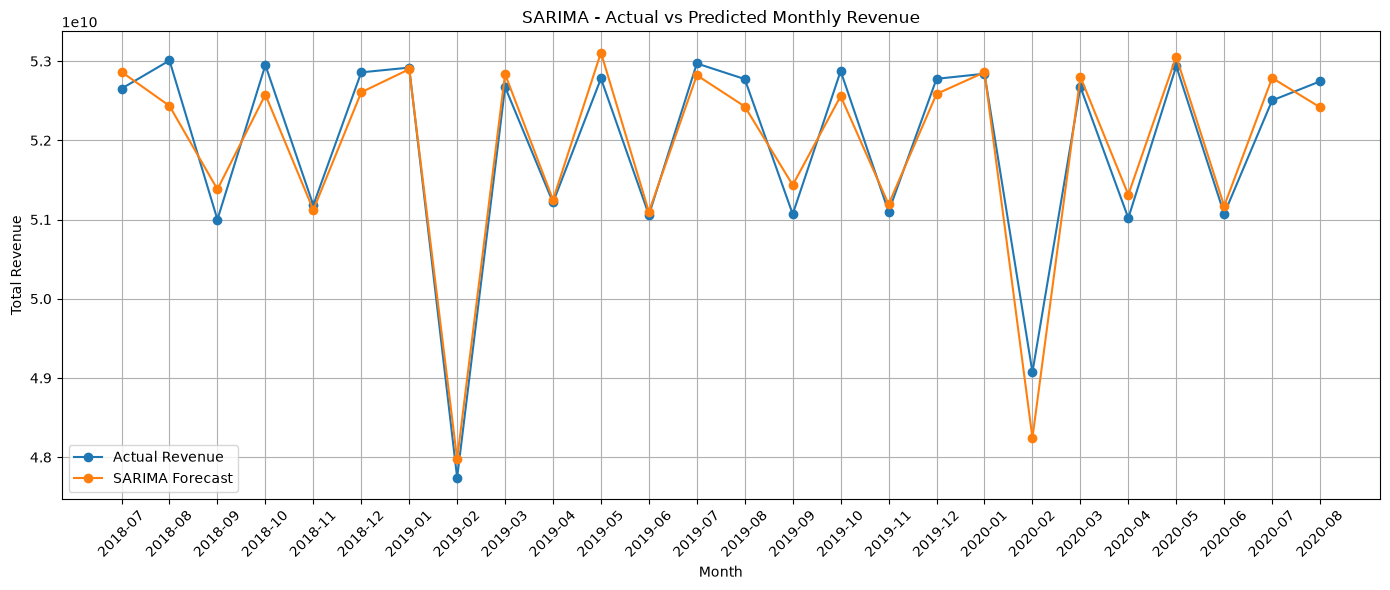

In [153]:
plt.figure(figsize=(14, 6))

plt.plot(
    test.index.astype(str),
    test["Total Revenue"].values,
    marker="o",
    label="Actual Revenue"
)

plt.plot(
    test.index.astype(str),
    sarima_predictions.values,
    marker="o",
    label="SARIMA Forecast"
)

plt.title("SARIMA - Actual vs Predicted Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [154]:
sarima_actual = test["Total Revenue"].values
sarima_pred = sarima_predictions.values

sarima_rmse = np.sqrt(
    mean_squared_error(
        sarima_actual,
        sarima_pred
    )
)

sarima_mae = mean_absolute_error(
    sarima_actual,
    sarima_pred
)

sarima_mape = np.mean(
    np.abs(
        (sarima_actual - sarima_pred)
        / sarima_actual
    )
) * 100

sarima_nrmse = (
    sarima_rmse /
    np.mean(sarima_actual)
)

sarima_mpe = np.mean(
    (sarima_actual - sarima_pred)
    / sarima_actual
) * 100

print("SARIMA RESULTS")
print("----------------")

print(f"RMSE  : {sarima_rmse:,.2f}")
print(f"MAE   : {sarima_mae:,.2f}")
print(f"NRMSE : {sarima_nrmse:.4f}")
print(f"MAPE  : {sarima_mape:.4f}%")
print(f"MPE   : {sarima_mpe:.4f}%")

SARIMA RESULTS
----------------
RMSE  : 299,778,021.77
MAE   : 239,391,841.00
NRMSE : 0.0058
MAPE  : 0.4631%
MPE   : 0.0460%


In [155]:
warnings.filterwarnings("ignore")

# Small controlled search space
p = [0, 1, 2]
d = [1]
q = [0, 1, 2]

P = [0, 1]
D = [0, 1]
Q = [0, 1]

results = []

for order in itertools.product(p, d, q):
    for seasonal in itertools.product(P, D, Q):

        seasonal_order = (
            seasonal[0],
            seasonal[1],
            seasonal[2],
            12
        )

        try:
            model = SARIMAX(
                train["Total Revenue"].astype(float),
                order=order,
                seasonal_order=seasonal_order,
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            fitted = model.fit(disp=False)

            results.append({
                "order": order,
                "seasonal_order": seasonal_order,
                "AIC": fitted.aic,
                "BIC": fitted.bic
            })

        except:
            continue

sarima_search = pd.DataFrame(results)

sarima_search = sarima_search.sort_values("AIC")

display(sarima_search.head(10))

,order,seasonal_order,AIC,BIC
23,"(0, 1, 2)","(1, 1, 1, 12)",3169.772771,3181.293096
47,"(1, 1, 2)","(1, 1, 1, 12)",3170.541502,3184.365892
71,"(2, 1, 2)","(1, 1, 1, 12)",3172.278232,3188.406688
19,"(0, 1, 2)","(0, 1, 1, 12)",3185.663634,3194.879894
43,"(1, 1, 2)","(0, 1, 1, 12)",3186.955399,3198.475725
67,"(2, 1, 2)","(0, 1, 1, 12)",3188.844759,3202.669149
54,"(2, 1, 0)","(1, 1, 0, 12)",3213.878953,3223.148905
62,"(2, 1, 1)","(1, 1, 0, 12)",3214.284634,3225.872074
70,"(2, 1, 2)","(1, 1, 0, 12)",3214.802708,3228.707637
55,"(2, 1, 0)","(1, 1, 1, 12)",3215.312103,3226.899543


In [156]:
best_sarima_model = SARIMAX(
    train["Total Revenue"].astype(float),
    order=(0, 1, 2),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

best_sarima_fit = best_sarima_model.fit(
    disp=False
)

print(best_sarima_fit.summary())

                                      SARIMAX Results                                       
Dep. Variable:                        Total Revenue   No. Observations:                  102
Model:             SARIMAX(0, 1, 2)x(1, 1, [1], 12)   Log Likelihood               -1579.886
Date:                              Sun, 13 Sep 2026   AIC                           3169.773
Time:                                      23:45:16   BIC                           3181.293
Sample:                                  01-31-2010   HQIC                          3174.368
                                       - 06-30-2018                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.6664      0.181     -3.680      0.000      -1.021      -0.311
ma.L2          0.17

In [157]:
best_sarima_predictions = best_sarima_fit.forecast(
    steps=len(test)
)

print("Forecast length:", len(best_sarima_predictions))

print("\nFirst 5 predictions:")
print(best_sarima_predictions.head())

Forecast length: 26

First 5 predictions:
2018-07    5.315973e+10
2018-08    5.277582e+10
2018-09    5.123618e+10
2018-10    5.290434e+10
2018-11    5.108683e+10
Freq: M, Name: predicted_mean, dtype: float64


In [158]:
best_sarima_actual = test["Total Revenue"].values
best_sarima_pred = best_sarima_predictions.values

best_sarima_rmse = np.sqrt(
    mean_squared_error(
        best_sarima_actual,
        best_sarima_pred
    )
)

best_sarima_mae = mean_absolute_error(
    best_sarima_actual,
    best_sarima_pred
)

best_sarima_mape = np.mean(
    np.abs(
        (best_sarima_actual - best_sarima_pred)
        / best_sarima_actual
    )
) * 100

best_sarima_nrmse = (
    best_sarima_rmse /
    np.mean(best_sarima_actual)
)

best_sarima_mpe = np.mean(
    (best_sarima_actual - best_sarima_pred)
    / best_sarima_actual
) * 100

print("TUNED SARIMA RESULTS")
print("--------------------")
print(f"RMSE  : {best_sarima_rmse:,.2f}")
print(f"MAE   : {best_sarima_mae:,.2f}")
print(f"NRMSE : {best_sarima_nrmse:.4f}")
print(f"MAPE  : {best_sarima_mape:.4f}%")
print(f"MPE   : {best_sarima_mpe:.4f}%")

TUNED SARIMA RESULTS
--------------------
RMSE  : 362,189,199.09
MAE   : 252,640,369.13
NRMSE : 0.0070
MAPE  : 0.4896%
MPE   : -0.2174%


# XGBoost

In [159]:
print("X_train_dense shape:", X_train_dense.shape)
print("y_train_dense shape:", y_train_dense.shape)

print("\nFirst XGBoost input:")
print(X_train_dense[0])

print("\nTarget:")
print(y_train_dense[0])

X_train_dense shape: (78, 24)
y_train_dense shape: (78,)

First XGBoost input:
[ 0.67766055 -0.46470394  0.68629868 -0.2723019   0.7190258   0.5396773
 -0.35592244  0.51243422 -0.49120876  0.66320586 -2.84398794  0.98460895
  0.71065358 -0.61018062  0.80571293 -0.42397536  0.67413018  0.49091239
 -0.54966226  0.77966838 -0.45137095  0.73009444 -3.06836641  0.70905165]

Target:
0.6788103208771884


In [160]:
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_dense,
    y_train_dense
)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.9
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [161]:
xgb_predictions_scaled = xgb_model.predict(
    X_test_dense
)

xgb_predictions = scaler.inverse_transform(
    xgb_predictions_scaled.reshape(-1, 1)
).flatten()

In [162]:
xgb_rmse = np.sqrt(
    mean_squared_error(
        actual_test,
        xgb_predictions
    )
)

xgb_mae = mean_absolute_error(
    actual_test,
    xgb_predictions
)

xgb_mape = np.mean(
    np.abs(
        (actual_test - xgb_predictions)
        / actual_test
    )
) * 100

xgb_nrmse = (
    xgb_rmse /
    np.mean(actual_test)
)

xgb_mpe = np.mean(
    (actual_test - xgb_predictions)
    / actual_test
) * 100

print("XGBOOST RESULTS")
print("----------------")
print(f"RMSE  : {xgb_rmse:,.2f}")
print(f"MAE   : {xgb_mae:,.2f}")
print(f"NRMSE : {xgb_nrmse:.4f}")
print(f"MAPE  : {xgb_mape:.4f}%")
print(f"MPE   : {xgb_mpe:.4f}%")

XGBOOST RESULTS
----------------
RMSE  : 388,034,665.82
MAE   : 222,865,408.00
NRMSE : 0.0075
MAPE  : 0.4414%
MPE   : -0.0789%


In [163]:
xgb_importance = pd.DataFrame({
    "Lag": [f"Lag {i}" for i in range(1, 25)],
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    "Importance",
    ascending=False
)

display(xgb_importance)

,Lag,Importance
11,Lag 12,0.542478
6,Lag 7,0.251234
23,Lag 24,0.079841
7,Lag 8,0.034701
19,Lag 20,0.031582
18,Lag 19,0.028893
5,Lag 6,0.004813
0,Lag 1,0.003535
22,Lag 23,0.002873
15,Lag 16,0.002279


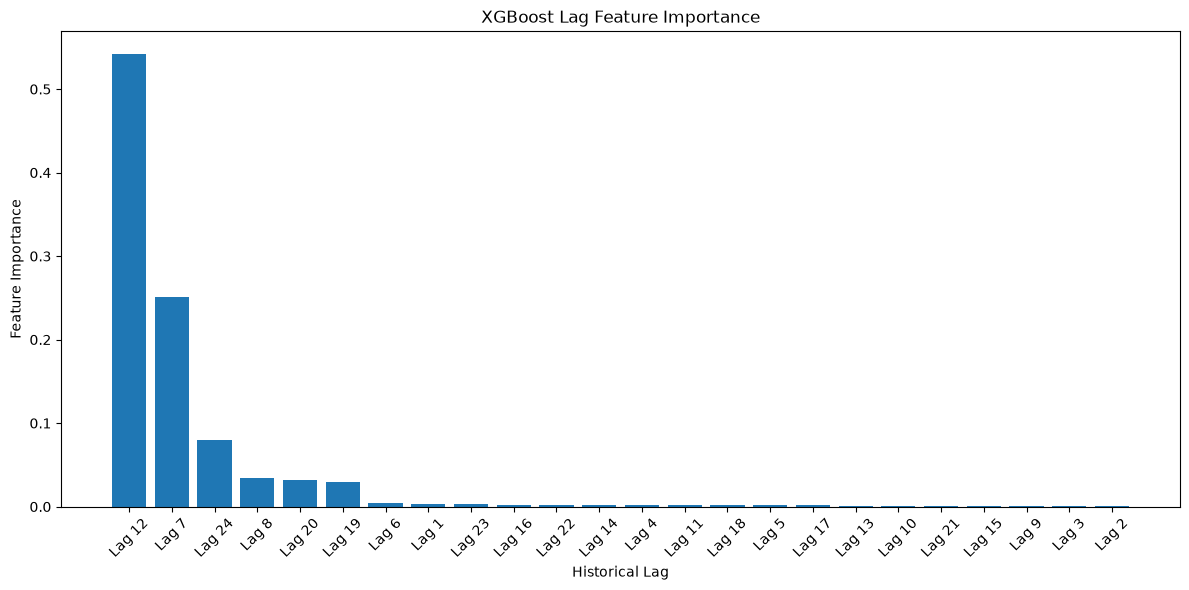

In [164]:
plt.figure(figsize=(12, 6))

plt.bar(
    xgb_importance["Lag"],
    xgb_importance["Importance"]
)

plt.title("XGBoost Lag Feature Importance")
plt.xlabel("Historical Lag")
plt.ylabel("Feature Importance")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# LSTM baseline.

In [165]:
X_train_lstm = X_train_dense.reshape(
    X_train_dense.shape[0],
    X_train_dense.shape[1],
    1
)

X_test_lstm = X_test_dense.reshape(
    X_test_dense.shape[0],
    X_test_dense.shape[1],
    1
)

print("Original training shape :", X_train_dense.shape)
print("LSTM training shape     :", X_train_lstm.shape)

print("Original test shape     :", X_test_dense.shape)
print("LSTM test shape         :", X_test_lstm.shape)

Original training shape : (78, 24)
LSTM training shape     : (78, 24, 1)
Original test shape     : (26, 24)
LSTM test shape         : (26, 24, 1)


In [167]:
class LSTMForecaster(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, num_layers=1):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        lstm_out, (hidden, cell) = self.lstm(x)

        last_hidden = hidden[-1]

        prediction = self.fc(last_hidden)

        return prediction

In [168]:
lstm_model = LSTMForecaster(
    input_size=1,
    hidden_size=32,
    num_layers=1
)

print(lstm_model)

LSTMForecaster(
  (lstm): LSTM(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)


# Convert NumPy arrays to PyTorch tensors

In [169]:
X_train_lstm_tensor = torch.tensor(
    X_train_lstm,
    dtype=torch.float32
)

y_train_lstm_tensor = torch.tensor(
    y_train_dense,
    dtype=torch.float32
).reshape(-1, 1)

X_test_lstm_tensor = torch.tensor(
    X_test_lstm,
    dtype=torch.float32
)

print("X train tensor:", X_train_lstm_tensor.shape)
print("y train tensor:", y_train_lstm_tensor.shape)
print("X test tensor :", X_test_lstm_tensor.shape)

X train tensor: torch.Size([78, 24, 1])
y train tensor: torch.Size([78, 1])
X test tensor : torch.Size([26, 24, 1])


In [170]:
# Create DataLoader
lstm_dataset = TensorDataset(
    X_train_lstm_tensor,
    y_train_lstm_tensor
)

lstm_loader = DataLoader(
    lstm_dataset,
    batch_size=16,
    shuffle=False
)

print("Number of training samples:", len(lstm_dataset))
print("Number of batches:", len(lstm_loader))

Number of training samples: 78
Number of batches: 5


In [172]:
# Loss and optimizer
lstm_criterion = nn.MSELoss()

lstm_optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

In [173]:
# Train for 100 epochs
torch.manual_seed(42)

lstm_model = LSTMForecaster(
    input_size=1,
    hidden_size=32,
    num_layers=1
)

lstm_criterion = nn.MSELoss()

lstm_optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

lstm_losses = []

for epoch in range(100):

    lstm_model.train()
    epoch_loss = 0.0

    for X_batch, y_batch in lstm_loader:

        # 1. Remove gradients from previous iteration
        lstm_optimizer.zero_grad()

        # 2. Forward pass
        predictions = lstm_model(X_batch)

        # 3. Calculate error
        loss = lstm_criterion(
            predictions,
            y_batch
        )

        # 4. Backpropagation
        loss.backward()

        # 5. Update weights
        lstm_optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(lstm_loader)
    lstm_losses.append(avg_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/100], "
            f"Loss: {avg_loss:.6f}"
        )

Epoch [10/100], Loss: 0.800270
Epoch [20/100], Loss: 0.264187
Epoch [30/100], Loss: 0.110009
Epoch [40/100], Loss: 0.100989
Epoch [50/100], Loss: 0.098034
Epoch [60/100], Loss: 0.095529
Epoch [70/100], Loss: 0.092257
Epoch [80/100], Loss: 0.088026
Epoch [90/100], Loss: 0.084613
Epoch [100/100], Loss: 0.081575


In [174]:
lstm_model.eval()

with torch.no_grad():
    lstm_predictions_scaled = (
        lstm_model(X_test_lstm_tensor)
        .cpu()
        .numpy()
        .flatten()
    )

print("Scaled prediction shape:", lstm_predictions_scaled.shape)
print("First 5 scaled predictions:")
print(lstm_predictions_scaled[:5])

Scaled prediction shape: (26,)
First 5 scaled predictions:
[ 0.8708856   0.7418242  -0.7888575   0.77175957 -0.86300147]


In [175]:
lstm_predictions = scaler.inverse_transform(
    lstm_predictions_scaled.reshape(-1, 1)
).flatten()

print("First 5 actual-scale predictions:")
print(lstm_predictions[:5])

First 5 actual-scale predictions:
[5.3098086e+10 5.2911616e+10 5.0700075e+10 5.2954870e+10 5.0592952e+10]


In [176]:
lstm_rmse = np.sqrt(
    mean_squared_error(
        actual_test,
        lstm_predictions
    )
)

lstm_mae = mean_absolute_error(
    actual_test,
    lstm_predictions
)

lstm_mape = np.mean(
    np.abs(
        (actual_test - lstm_predictions)
        / actual_test
    )
) * 100

lstm_nrmse = (
    lstm_rmse /
    np.mean(actual_test)
)

lstm_mpe = np.mean(
    (actual_test - lstm_predictions)
    / actual_test
) * 100

print("LSTM RESULTS")
print("----------------")
print(f"RMSE  : {lstm_rmse:,.2f}")
print(f"MAE   : {lstm_mae:,.2f}")
print(f"NRMSE : {lstm_nrmse:.4f}")
print(f"MAPE  : {lstm_mape:.4f}%")
print(f"MPE   : {lstm_mpe:.4f}%")

LSTM RESULTS
----------------
RMSE  : 293,499,008.47
MAE   : 210,090,768.00
NRMSE : 0.0057
MAPE  : 0.4095%
MPE   : 0.1123%


# lag-selection ablation

In [177]:
paper_lags = [1, 2, 7, 12]

acf_lags = [1, 5, 6, 11, 12, 13, 24]

combined_lags = [1, 2, 5, 6, 7, 11, 12, 13, 24]

print("Paper lags    :", paper_lags)
print("ACF lags      :", acf_lags)
print("Combined lags :", combined_lags)

Paper lags    : [1, 2, 7, 12]
ACF lags      : [1, 5, 6, 11, 12, 13, 24]
Combined lags : [1, 2, 5, 6, 7, 11, 12, 13, 24]


# Create a fair aligned dataset

In [179]:
def create_aligned_lag_samples(series, lags, start_index=24):
    
    X = []
    y = []

    for i in range(start_index, len(series)):
        
        # Extract selected historical lags
        lag_values = [
            series[i - lag]
            for lag in lags
        ]

        X.append(lag_values)
        y.append(series[i])

    return np.array(X), np.array(y)

# Create all three training datasets

In [180]:
X_train_paper, y_train_paper = create_aligned_lag_samples(
    train_scaled,
    paper_lags,
    start_index=24
)

X_train_acf, y_train_acf = create_aligned_lag_samples(
    train_scaled,
    acf_lags,
    start_index=24
)

X_train_combined, y_train_combined = create_aligned_lag_samples(
    train_scaled,
    combined_lags,
    start_index=24
)

print("Paper    :", X_train_paper.shape, y_train_paper.shape)
print("ACF      :", X_train_acf.shape, y_train_acf.shape)
print("Combined :", X_train_combined.shape, y_train_combined.shape)

Paper    : (78, 4) (78,)
ACF      : (78, 7) (78,)
Combined : (78, 9) (78,)


In [181]:
def create_test_lag_samples(train_series, test_series, lags):
    
    history = np.concatenate([
        train_series,
        test_series
    ])
    
    X_test = []
    
    train_len = len(train_series)
    
    for i in range(train_len, train_len + len(test_series)):
        
        lag_values = [
            history[i - lag]
            for lag in lags
        ]
        
        X_test.append(lag_values)
    
    return np.array(X_test)

In [182]:
X_test_paper = create_test_lag_samples(
    train_scaled,
    test_scaled,
    paper_lags
)

X_test_acf = create_test_lag_samples(
    train_scaled,
    test_scaled,
    acf_lags
)

X_test_combined = create_test_lag_samples(
    train_scaled,
    test_scaled,
    combined_lags
)

print("Paper test    :", X_test_paper.shape)
print("ACF test      :", X_test_acf.shape)
print("Combined test :", X_test_combined.shape)

Paper test    : (26, 4)
ACF test      : (26, 7)
Combined test : (26, 9)


# Training helper

In [183]:
def train_vaticinator_variant(
    X_train,
    y_train,
    X_test,
    lags,
    seed=42,
    epochs=100,
    batch_size=16,
    lr=1e-4
):
    
    # Reproducibility
    torch.manual_seed(seed)

    # Convert arrays to tensors
    X_train_tensor = torch.tensor(
        X_train,
        dtype=torch.float32
    ).unsqueeze(-1)

    y_train_tensor = torch.tensor(
        y_train,
        dtype=torch.float32
    )

    X_test_tensor = torch.tensor(
        X_test,
        dtype=torch.float32
    ).unsqueeze(-1)

    # DataLoader
    dataset = TensorDataset(
        X_train_tensor,
        y_train_tensor
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False
    )

    # Same Vaticinator architecture
    model_variant = Vaticinator(
        lags=lags,
        d_model=32,
        nhead=8,
        num_layers=3,
        dim_feedforward=128
    )

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model_variant.parameters(),
        lr=lr
    )

    # Training
    model_variant.train()

    for epoch in range(epochs):

        epoch_loss = 0.0

        for X_batch, y_batch in loader:

            optimizer.zero_grad()

            predictions = model_variant(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

    # Test prediction
    model_variant.eval()

    with torch.no_grad():

        predictions_scaled = (
            model_variant(X_test_tensor)
            .cpu()
            .numpy()
            .flatten()
        )

    # Back to revenue scale
    predictions_actual = scaler.inverse_transform(
        predictions_scaled.reshape(-1, 1)
    ).flatten()

    # Metrics
    rmse = np.sqrt(
        mean_squared_error(
            actual_test,
            predictions_actual
        )
    )

    mae = mean_absolute_error(
        actual_test,
        predictions_actual
    )

    mape = np.mean(
        np.abs(
            (actual_test - predictions_actual)
            / actual_test
        )
    ) * 100

    nrmse = rmse / np.mean(actual_test)

    mpe = np.mean(
        (actual_test - predictions_actual)
        / actual_test
    ) * 100

    return {
        "model": model_variant,
        "predictions": predictions_actual,
        "RMSE": rmse,
        "MAE": mae,
        "NRMSE": nrmse,
        "MAPE": mape,
        "MPE": mpe
    }

# Train the three variants

In [184]:
paper_result = train_vaticinator_variant(
    X_train_paper,
    y_train_paper,
    X_test_paper,
    paper_lags
)

acf_result = train_vaticinator_variant(
    X_train_acf,
    y_train_acf,
    X_test_acf,
    acf_lags
)

combined_result = train_vaticinator_variant(
    X_train_combined,
    y_train_combined,
    X_test_combined,
    combined_lags
)

In [185]:
print("LAG ABLATION RESULTS")
print("--------------------")

for name, result in [
    ("Paper", paper_result),
    ("ACF", acf_result),
    ("Combined", combined_result)
]:
    
    print(f"\n{name}")
    print(f"RMSE  : {result['RMSE']:,.2f}")
    print(f"MAE   : {result['MAE']:,.2f}")
    print(f"NRMSE : {result['NRMSE']:.4f}")
    print(f"MAPE  : {result['MAPE']:.4f}%")
    print(f"MPE   : {result['MPE']:.4f}%")

LAG ABLATION RESULTS
--------------------

Paper
RMSE  : 266,931,860.94
MAE   : 191,228,224.00
NRMSE : 0.0051
MAPE  : 0.3749%
MPE   : -0.1004%

ACF
RMSE  : 289,681,945.20
MAE   : 213,336,544.00
NRMSE : 0.0056
MAPE  : 0.4176%
MPE   : -0.0026%

Combined
RMSE  : 281,055,076.77
MAE   : 209,696,288.00
NRMSE : 0.0054
MAPE  : 0.4108%
MPE   : 0.0226%


In [186]:
combined_lags = [1, 2, 5, 6, 7, 11, 12, 13, 24]

In [187]:
class StandardPEVaticinator(Vaticinator):

    def lag_positional_encoding(self, x):

        # Sequential positions instead of actual lag distances
        positions = torch.arange(
            1,
            len(self.lags) + 1,
            dtype=torch.float32,
            device=x.device
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(
                0,
                self.d_model,
                2,
                device=x.device
            ).float()
            * (-math.log(10000.0) / self.d_model)
        )

        pe = torch.zeros(
            len(self.lags),
            self.d_model,
            device=x.device
        )

        pe[:, 0::2] = torch.sin(
            positions * div_term
        )

        pe[:, 1::2] = torch.cos(
            positions * div_term
        )

        return x + pe.unsqueeze(0)

In [188]:
print("Actual lag-aware positions:")
print(combined_lags)

print("\nStandard sequential positions:")
print(list(range(1, len(combined_lags) + 1)))

Actual lag-aware positions:
[1, 2, 5, 6, 7, 11, 12, 13, 24]

Standard sequential positions:
[1, 2, 3, 4, 5, 6, 7, 8, 9]


In [189]:
def train_standard_pe_variant(
    X_train,
    y_train,
    X_test,
    lags,
    seed=42,
    epochs=100,
    batch_size=16,
    lr=1e-4
):

    torch.manual_seed(seed)

    X_train_tensor = torch.tensor(
        X_train,
        dtype=torch.float32
    ).unsqueeze(-1)

    y_train_tensor = torch.tensor(
        y_train,
        dtype=torch.float32
    )

    X_test_tensor = torch.tensor(
        X_test,
        dtype=torch.float32
    ).unsqueeze(-1)

    dataset = TensorDataset(
        X_train_tensor,
        y_train_tensor
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False
    )

    model_standard_pe = StandardPEVaticinator(
        lags=lags,
        d_model=32,
        nhead=8,
        num_layers=3,
        dim_feedforward=128
    )

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model_standard_pe.parameters(),
        lr=lr
    )

    model_standard_pe.train()

    for epoch in range(epochs):

        for X_batch, y_batch in loader:

            optimizer.zero_grad()

            predictions = model_standard_pe(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            loss.backward()
            optimizer.step()

    model_standard_pe.eval()

    with torch.no_grad():

        predictions_scaled = (
            model_standard_pe(X_test_tensor)
            .cpu()
            .numpy()
            .flatten()
        )

    predictions_actual = scaler.inverse_transform(
        predictions_scaled.reshape(-1, 1)
    ).flatten()

    rmse = np.sqrt(
        mean_squared_error(
            actual_test,
            predictions_actual
        )
    )

    mae = mean_absolute_error(
        actual_test,
        predictions_actual
    )

    mape = np.mean(
        np.abs(
            (actual_test - predictions_actual)
            / actual_test
        )
    ) * 100

    nrmse = rmse / np.mean(actual_test)

    mpe = np.mean(
        (actual_test - predictions_actual)
        / actual_test
    ) * 100

    return {
        "model": model_standard_pe,
        "predictions": predictions_actual,
        "RMSE": rmse,
        "MAE": mae,
        "NRMSE": nrmse,
        "MAPE": mape,
        "MPE": mpe
    }

In [190]:
standard_pe_result = train_standard_pe_variant(
    X_train_combined,
    y_train_combined,
    X_test_combined,
    combined_lags
)

In [191]:
print("POSITIONAL ENCODING ABLATION")
print("----------------------------")

print("\nLag-aware PE")
print(f"RMSE  : {combined_result['RMSE']:,.2f}")
print(f"MAE   : {combined_result['MAE']:,.2f}")
print(f"NRMSE : {combined_result['NRMSE']:.4f}")
print(f"MAPE  : {combined_result['MAPE']:.4f}%")
print(f"MPE   : {combined_result['MPE']:.4f}%")

print("\nStandard sequential PE")
print(f"RMSE  : {standard_pe_result['RMSE']:,.2f}")
print(f"MAE   : {standard_pe_result['MAE']:,.2f}")
print(f"NRMSE : {standard_pe_result['NRMSE']:.4f}")
print(f"MAPE  : {standard_pe_result['MAPE']:.4f}%")
print(f"MPE   : {standard_pe_result['MPE']:.4f}%")

POSITIONAL ENCODING ABLATION
----------------------------

Lag-aware PE
RMSE  : 281,055,076.77
MAE   : 209,696,288.00
NRMSE : 0.0054
MAPE  : 0.4108%
MPE   : 0.0226%

Standard sequential PE
RMSE  : 277,820,221.71
MAE   : 207,722,496.00
NRMSE : 0.0053
MAPE  : 0.4074%
MPE   : 0.0248%


In [192]:
sparse_model = combined_result["model"]

sparse_input = torch.tensor(
    X_test_combined,
    dtype=torch.float32
).unsqueeze(-1)

dense_input = torch.tensor(
    X_test_dense,
    dtype=torch.float32
).unsqueeze(-1)

print("Sparse input shape:", sparse_input.shape)
print("Dense input shape :", dense_input.shape)

Sparse input shape: torch.Size([26, 9, 1])
Dense input shape : torch.Size([26, 24, 1])


In [194]:
def measure_inference_time(model, X, warmup=50, repeats=500):

    model.eval()

    # Warm-up runs
    with torch.no_grad():
        for _ in range(warmup):
            _ = model(X)

    times = []

    # Timed runs
    with torch.no_grad():

        for _ in range(repeats):

            start = time.perf_counter()

            _ = model(X)

            end = time.perf_counter()

            times.append(
                (end - start) * 1000
            )

    return {
        "mean_ms": np.mean(times),
        "median_ms": np.median(times),
        "std_ms": np.std(times)
    }

In [195]:
sparse_time = measure_inference_time(
    sparse_model,
    sparse_input
)

dense_time = measure_inference_time(
    dense_model,
    dense_input
)

print("EFFICIENCY RESULTS")
print("------------------")

print("\nSparse Vaticinator (9 tokens)")
print(f"Mean   : {sparse_time['mean_ms']:.4f} ms")
print(f"Median : {sparse_time['median_ms']:.4f} ms")
print(f"Std    : {sparse_time['std_ms']:.4f} ms")

print("\nDense Transformer (24 tokens)")
print(f"Mean   : {dense_time['mean_ms']:.4f} ms")
print(f"Median : {dense_time['median_ms']:.4f} ms")
print(f"Std    : {dense_time['std_ms']:.4f} ms")

token_reduction = (
    1 - 9 / 24
) * 100

print(
    f"\nInput token reduction: "
    f"{token_reduction:.1f}%"
)

EFFICIENCY RESULTS
------------------

Sparse Vaticinator (9 tokens)
Mean   : 2.4785 ms
Median : 2.5760 ms
Std    : 0.5721 ms

Dense Transformer (24 tokens)
Mean   : 3.6173 ms
Median : 3.6785 ms
Std    : 0.6681 ms

Input token reduction: 62.5%


# Reversed LSTM

In [196]:
X_train_lstm = X_train_dense[:, ::-1].copy()
X_test_lstm = X_test_dense[:, ::-1].copy()

print("Original dense shape:", X_train_dense.shape)
print("LSTM input shape    :", X_train_lstm.shape)

print("\nOriginal first sample:")
print(X_train_dense[0])

print("\nChronological LSTM sample:")
print(X_train_lstm[0])

Original dense shape: (78, 24)
LSTM input shape    : (78, 24)

Original first sample:
[ 0.67766055 -0.46470394  0.68629868 -0.2723019   0.7190258   0.5396773
 -0.35592244  0.51243422 -0.49120876  0.66320586 -2.84398794  0.98460895
  0.71065358 -0.61018062  0.80571293 -0.42397536  0.67413018  0.49091239
 -0.54966226  0.77966838 -0.45137095  0.73009444 -3.06836641  0.70905165]

Chronological LSTM sample:
[ 0.70905165 -3.06836641  0.73009444 -0.45137095  0.77966838 -0.54966226
  0.49091239  0.67413018 -0.42397536  0.80571293 -0.61018062  0.71065358
  0.98460895 -2.84398794  0.66320586 -0.49120876  0.51243422 -0.35592244
  0.5396773   0.7190258  -0.2723019   0.68629868 -0.46470394  0.67766055]


In [197]:
X_train_lstm_tensor = torch.tensor(
    X_train_lstm,
    dtype=torch.float32
).unsqueeze(-1)

X_test_lstm_tensor = torch.tensor(
    X_test_lstm,
    dtype=torch.float32
).unsqueeze(-1)

y_train_lstm_tensor = torch.tensor(
    y_train_dense,
    dtype=torch.float32
)

print("Training:", X_train_lstm_tensor.shape)
print("Test    :", X_test_lstm_tensor.shape)
print("Target  :", y_train_lstm_tensor.shape)

Training: torch.Size([78, 24, 1])
Test    : torch.Size([26, 24, 1])
Target  : torch.Size([78])


In [198]:
torch.manual_seed(42)

lstm_model_corrected = LSTMForecaster(
    input_size=1,
    hidden_size=32,
    num_layers=1
)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_model_corrected.parameters(),
    lr=0.001
)

train_dataset = TensorDataset(
    X_train_lstm_tensor,
    y_train_lstm_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=False
)

num_epochs = 100

for epoch in range(num_epochs):

    lstm_model_corrected.train()

    epoch_loss = 0.0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        predictions = lstm_model_corrected(X_batch)

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        optimizer.step()

        epoch_loss += loss.item()

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"{epoch_loss / len(train_loader):.6f}"
        )

Epoch 10: 0.971907
Epoch 20: 0.971799
Epoch 30: 0.971653
Epoch 40: 0.971379
Epoch 50: 0.970665
Epoch 60: 0.969471
Epoch 70: 0.969056
Epoch 80: 0.968876
Epoch 90: 0.968767
Epoch 100: 0.968688


In [200]:
lstm_model_corrected.eval()

with torch.no_grad():

    lstm_predictions_scaled = (
        lstm_model_corrected(
            X_test_lstm_tensor
        )
        .cpu()
        .numpy()
        .flatten()
    )

lstm_predictions_actual = scaler.inverse_transform(
    lstm_predictions_scaled.reshape(-1, 1)
).flatten()


In [201]:
lstm_rmse_corrected = np.sqrt(
    mean_squared_error(
        actual_test,
        lstm_predictions_actual
    )
)

lstm_mae_corrected = mean_absolute_error(
    actual_test,
    lstm_predictions_actual
)

lstm_nrmse_corrected = (
    lstm_rmse_corrected
    / np.mean(actual_test)
)

lstm_mape_corrected = np.mean(
    np.abs(
        (actual_test - lstm_predictions_actual)
        / actual_test
    )
) * 100

lstm_mpe_corrected = np.mean(
    (actual_test - lstm_predictions_actual)
    / actual_test
) * 100

print("CORRECTED LSTM RESULTS")
print("----------------------")
print(f"RMSE  : {lstm_rmse_corrected:,.2f}")
print(f"MAE   : {lstm_mae_corrected:,.2f}")
print(f"NRMSE : {lstm_nrmse_corrected:.4f}")
print(f"MAPE  : {lstm_mape_corrected:.4f}%")
print(f"MPE   : {lstm_mpe_corrected:.4f}%")

CORRECTED LSTM RESULTS
----------------------
RMSE  : 1,281,828,620.72
MAE   : 1,065,172,224.00
NRMSE : 0.0247
MAPE  : 2.0792%
MPE   : 0.0309%


In [202]:
print("First 10 actual values:")
print(actual_test[:10])

print("\nFirst 10 LSTM predictions:")
print(lstm_predictions_actual[:10])

print("\nActual mean:")
print(np.mean(actual_test))

print("\nPrediction mean:")
print(np.mean(lstm_predictions_actual))

print("\nPrediction min/max:")
print(
    np.min(lstm_predictions_actual),
    np.max(lstm_predictions_actual)
)

First 10 actual values:
[5.2653105e+10 5.3008339e+10 5.1000426e+10 5.2950340e+10 5.1182068e+10
 5.2858544e+10 5.2918551e+10 4.7742456e+10 5.2673712e+10 5.1215495e+10]

First 10 LSTM predictions:
[5.2014666e+10 5.1998175e+10 5.1971650e+10 5.1974996e+10 5.1922907e+10
 5.1916583e+10 5.1873534e+10 5.1825451e+10 5.1838988e+10 5.1842646e+10]

Actual mean:
5.194127e+10

Prediction mean:
5.189178e+10

Prediction min/max:
5.178827e+10 5.2014666e+10


In [203]:
lstm_model_corrected.eval()

with torch.no_grad():
    train_pred_scaled = (
        lstm_model_corrected(X_train_lstm_tensor)
        .cpu()
        .numpy()
        .flatten()
    )

train_pred_actual = scaler.inverse_transform(
    train_pred_scaled.reshape(-1, 1)
).flatten()

train_actual = scaler.inverse_transform(
    y_train_lstm_tensor
    .cpu()
    .numpy()
    .reshape(-1, 1)
).flatten()

train_rmse = np.sqrt(
    mean_squared_error(
        train_actual,
        train_pred_actual
    )
)

train_mape = np.mean(
    np.abs(
        (train_actual - train_pred_actual)
        / train_actual
    )
) * 100

print("LSTM TRAINING PERFORMANCE")
print("-------------------------")
print(f"RMSE : {train_rmse:,.2f}")
print(f"MAPE : {train_mape:.4f}%")

LSTM TRAINING PERFORMANCE
-------------------------
RMSE : 1,408,539,596.55
MAPE : 2.2349%


In [204]:
class LSTMForecasterImproved(nn.Module):
    def __init__(
        self,
        input_size=1,
        hidden_size=64,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        lstm_out, (hidden, cell) = self.lstm(x)

        last_hidden = hidden[-1]

        prediction = self.fc(
            last_hidden
        )

        return prediction.squeeze(-1)

In [205]:
torch.manual_seed(42)

lstm_model_improved = LSTMForecasterImproved()

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_model_improved.parameters(),
    lr=0.001
)

train_dataset = TensorDataset(
    X_train_lstm_tensor,
    y_train_lstm_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=False
)

num_epochs = 300

for epoch in range(num_epochs):

    lstm_model_improved.train()

    epoch_loss = 0.0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        predictions = lstm_model_improved(
            X_batch
        )

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        optimizer.step()

        epoch_loss += loss.item()

    if (epoch + 1) % 25 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"{epoch_loss / len(train_loader):.6f}"
        )

Epoch 25: 0.547534
Epoch 50: 0.205524
Epoch 75: 0.069791
Epoch 100: 0.053414
Epoch 125: 0.039406
Epoch 150: 0.041542
Epoch 175: 0.031535
Epoch 200: 0.021867
Epoch 225: 0.023502
Epoch 250: 0.022060
Epoch 275: 0.019231
Epoch 300: 0.017075


In [206]:
lstm_model_improved.eval()

with torch.no_grad():

    train_pred_scaled = (
        lstm_model_improved(
            X_train_lstm_tensor
        )
        .cpu()
        .numpy()
        .flatten()
    )

train_pred_actual = scaler.inverse_transform(
    train_pred_scaled.reshape(-1, 1)
).flatten()

train_actual = scaler.inverse_transform(
    y_train_lstm_tensor
    .cpu()
    .numpy()
    .reshape(-1, 1)
).flatten()

train_rmse = np.sqrt(
    mean_squared_error(
        train_actual,
        train_pred_actual
    )
)

train_mape = np.mean(
    np.abs(
        (train_actual - train_pred_actual)
        / train_actual
    )
) * 100

print("IMPROVED LSTM TRAINING PERFORMANCE")
print("----------------------------------")
print(f"RMSE : {train_rmse:,.2f}")
print(f"MAPE : {train_mape:.4f}%")

IMPROVED LSTM TRAINING PERFORMANCE
----------------------------------
RMSE : 134,061,004.50
MAPE : 0.1920%


In [207]:
lstm_model_improved.eval()

with torch.no_grad():

    lstm_predictions_scaled = (
        lstm_model_improved(
            X_test_lstm_tensor
        )
        .cpu()
        .numpy()
        .flatten()
    )

lstm_predictions_actual = scaler.inverse_transform(
    lstm_predictions_scaled.reshape(-1, 1)
).flatten()

In [208]:
lstm_rmse_final = np.sqrt(
    mean_squared_error(
        actual_test,
        lstm_predictions_actual
    )
)

lstm_mae_final = mean_absolute_error(
    actual_test,
    lstm_predictions_actual
)

lstm_nrmse_final = (
    lstm_rmse_final
    / np.mean(actual_test)
)

lstm_mape_final = np.mean(
    np.abs(
        (actual_test - lstm_predictions_actual)
        / actual_test
    )
) * 100

lstm_mpe_final = np.mean(
    (actual_test - lstm_predictions_actual)
    / actual_test
) * 100

print("FINAL IMPROVED LSTM TEST RESULTS")
print("--------------------------------")
print(f"RMSE  : {lstm_rmse_final:,.2f}")
print(f"MAE   : {lstm_mae_final:,.2f}")
print(f"NRMSE : {lstm_nrmse_final:.4f}")
print(f"MAPE  : {lstm_mape_final:.4f}%")
print(f"MPE   : {lstm_mpe_final:.4f}%")

FINAL IMPROVED LSTM TEST RESULTS
--------------------------------
RMSE  : 342,678,249.98
MAE   : 226,418,848.00
NRMSE : 0.0066
MAPE  : 0.4419%
MPE   : -0.2481%


# Final baseline comparison

In [209]:
baseline_results = pd.DataFrame({
    "Model": [
        "Vaticinator (Original 9-lag)",
        "Dense Transformer",
        "LSTM (Chronological)",
        "XGBoost",
        "SARIMA (Initial)",
        "SARIMA (AIC-selected)",
        "Seasonal Naive"
    ],
    "RMSE_Million": [
        282.58,
        288.32,
        342.68,
        388.03,
        299.78,
        362.19,
        338.96
    ],
    "MAPE_Percent": [
        0.4118,
        0.4283,
        0.4419,
        0.4414,
        0.4631,
        0.4896,
        0.4119
    ]
})

baseline_results = baseline_results.sort_values(
    "RMSE_Million"
).reset_index(drop=True)

baseline_results

,Model,RMSE_Million,MAPE_Percent
0,Vaticinator (Original 9-lag),282.58,0.4118
1,Dense Transformer,288.32,0.4283
2,SARIMA (Initial),299.78,0.4631
3,Seasonal Naive,338.96,0.4119
4,LSTM (Chronological),342.68,0.4419
5,SARIMA (AIC-selected),362.19,0.4896
6,XGBoost,388.03,0.4414


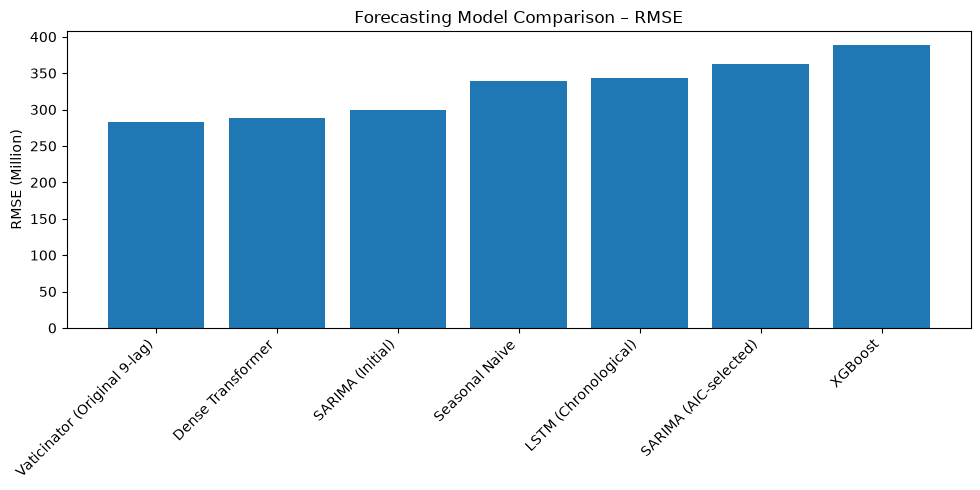

In [211]:
plt.figure(figsize=(10, 5))

plt.bar(
    baseline_results["Model"],
    baseline_results["RMSE_Million"]
)

plt.ylabel("RMSE (Million)")
plt.title("Forecasting Model Comparison – RMSE")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

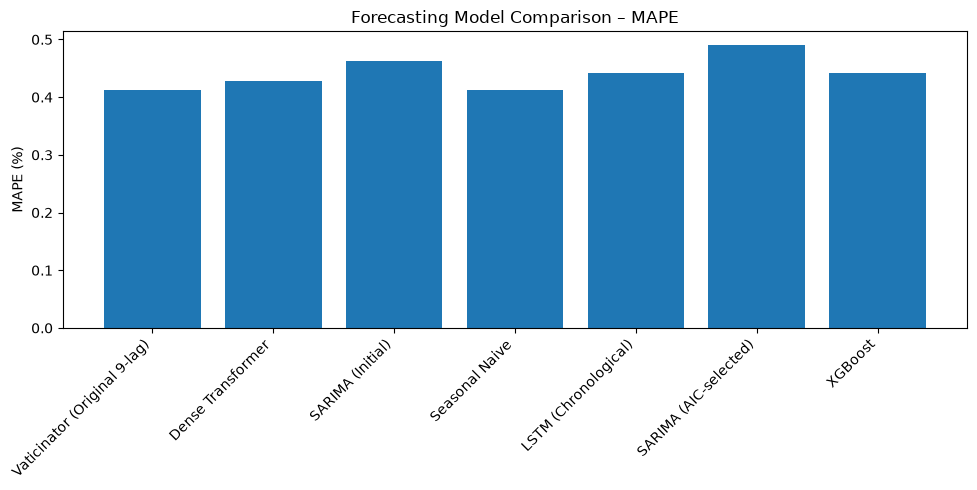

In [212]:
plt.figure(figsize=(10, 5))

plt.bar(
    baseline_results["Model"],
    baseline_results["MAPE_Percent"]
)

plt.ylabel("MAPE (%)")
plt.title("Forecasting Model Comparison – MAPE")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

# Lag-selection ablation

In [213]:
lag_ablation_results = pd.DataFrame({
    "Lag Strategy": [
        "Paper Lags",
        "ACF Lags",
        "Combined Lags"
    ],
    "Lags": [
        "[1, 2, 7, 12]",
        "[1, 5, 6, 11, 12, 13, 24]",
        "[1, 2, 5, 6, 7, 11, 12, 13, 24]"
    ],
    "Tokens": [
        4,
        7,
        9
    ],
    "RMSE_Million": [
        266.93,
        289.68,
        281.06
    ],
    "MAPE_Percent": [
        0.3749,
        0.4176,
        0.4108
    ]
})

lag_ablation_results

,Lag Strategy,Lags,Tokens,RMSE_Million,MAPE_Percent
0,Paper Lags,"[1, 2, 7, 12]",4,266.93,0.3749
1,ACF Lags,"[1, 5, 6, 11, 12, 13, 24]",7,289.68,0.4176
2,Combined Lags,"[1, 2, 5, 6, 7, 11, 12, 13, 24]",9,281.06,0.4108


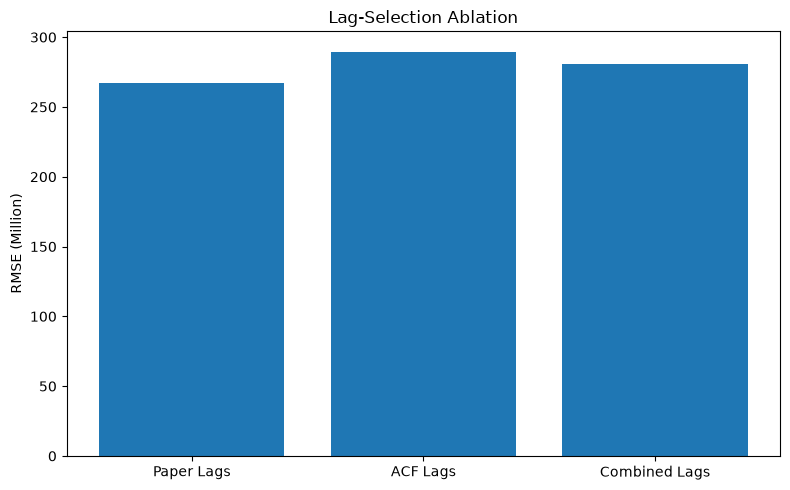

In [214]:
plt.figure(figsize=(8, 5))

plt.bar(
    lag_ablation_results["Lag Strategy"],
    lag_ablation_results["RMSE_Million"]
)

plt.ylabel("RMSE (Million)")
plt.title("Lag-Selection Ablation")

plt.tight_layout()
plt.show()

# PE and efficiency summary

In [215]:
pe_results = pd.DataFrame({
    "Positional Encoding": [
        "Lag-Aware PE",
        "Standard Sequential PE"
    ],
    "RMSE_Million": [
        281.06,
        277.82
    ],
    "MAPE_Percent": [
        0.4108,
        0.4074
    ]
})

pe_results

,Positional Encoding,RMSE_Million,MAPE_Percent
0,Lag-Aware PE,281.06,0.4108
1,Standard Sequential PE,277.82,0.4074


In [216]:
efficiency_results = pd.DataFrame({
    "Model": [
        "Sparse Vaticinator",
        "Dense Transformer"
    ],
    "Tokens": [
        9,
        24
    ],
    "Mean_Inference_ms": [
        2.4785,
        3.6173
    ],
    "Median_Inference_ms": [
        2.5760,
        3.6785
    ]
})

efficiency_results

,Model,Tokens,Mean_Inference_ms,Median_Inference_ms
0,Sparse Vaticinator,9,2.4785,2.5760
1,Dense Transformer,24,3.6173,3.6785


In [217]:
token_reduction = (
    1 - 9 / 24
) * 100

median_time_reduction = (
    1 - 2.5760 / 3.6785
) * 100

mean_time_reduction = (
    1 - 2.4785 / 3.6173
) * 100

print(
    f"Input token reduction      : "
    f"{token_reduction:.1f}%"
)

print(
    f"Median inference reduction : "
    f"{median_time_reduction:.1f}%"
)

print(
    f"Mean inference reduction   : "
    f"{mean_time_reduction:.1f}%"
)

Input token reduction      : 62.5%
Median inference reduction : 30.0%
Mean inference reduction   : 31.5%
